<a href="https://colab.research.google.com/github/rishiks29/Retro_Project1/blob/main/Regeneron_STS_VACCINE_NIS_TEEN_Pooled.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
-- Can Yesterday's Model Predict Tomorrow's Outcome?
-- Temporal Reliability Across NIS-Teen 2019-2024
-- Regeneron STS research analysis.
-- Author: Rishik Shenolikar
'''

from __future__ import annotations

import json
import math
import os
import shutil
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr, wasserstein_distance, linregress

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    GroupKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    import statsmodels.formula.api as smf
    STATSMODELS_AVAILABLE = True
except Exception:
    STATSMODELS_AVAILABLE = False

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# 1. CONFIGURATION
# ============================================================

YEARS = [2019, 2020, 2021, 2022, 2023, 2024]

# ---- EDIT ONLY DATA_ROOT / FILE_NAMES IF NEEDED ----
# Option A: upload the six CSV files directly into /content.
# Option B: mount Google Drive and set DATA_ROOT to the folder containing them.
# Outside Colab, change this to the folder containing the six NIS-Teen CSV files.
DATA_ROOT = Path("/content/drive/MyDrive/NIS_TEEN_CSV")

FILE_NAMES = {
    2019: "NISTEENPUF19.csv",
    2020: "NISTEENPUF20.csv",
    2021: "NISTEENPUF21.csv",
    2022: "NISTEENPUF22.csv",
    2023: "NISTEENPUF23.csv",
    2024: "NISTEENPUF24.csv",
}

DATA_PATHS = {
    year: DATA_ROOT / filename
    for year, filename in FILE_NAMES.items()
}

OUTPUT_DIR = Path("/content/yesterdays_model_tomorrows_outcome")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.30
CV_FOLDS = 5
CLASSIFICATION_THRESHOLD = 0.50


# Make sure to keep False while debugging paths/codings. Set True for the locked final run.
FINAL_RUN = True

# Bootstrap uncertainty for source-vs-future deterioration.
# running 1000 for the entire process took very long time, so I only ran 1000 bootstraps for the logest transport.
N_BOOTSTRAP = 1000 if FINAL_RUN else 250

# Permutation importance is exploratory and not required for the primary report .
PERMUTATION_REPEATS = 10 if FINAL_RUN else 3

# Hyperparameter optimization metric within each source year.
# AUROC is retained for continuity with the earlier modeling work.
TUNING_SCORING = "roc_auc"

# Main computation switches
RUN_XGBOOST = True
RUN_RANDOM_FOREST = True
RUN_HIST_GRADIENT_BOOSTING = False

# These are the analyses central to the Regeneron project.
RUN_DELTA_BOOTSTRAP = True
RUN_RISK_STRATA = True
RUN_TEMPORAL_MODEL_SELECTION = True
RUN_SHIFT_DIAGNOSTICS = True
RUN_PREDICTOR_IMPORTANCE = True
RUN_WEIGHTED_EVALUATION = True

# Secondary/supportive subgroup temporal-stability analysis.
RUN_SUBGROUP_STABILITY = True
SUBGROUP_VARS = [
    "SEX",
    "RACEETHK",
    "INCPOV1",
    "INS_STAT2_I",
    "STATE",
]
MIN_SUBGROUP_N = 200
MIN_SUBGROUP_POSITIVES = 30
MIN_SUBGROUP_NEGATIVES = 30

# Top-k overlap used for feature-stability summaries.
FEATURE_STABILITY_TOP_K = 5

# Older experimental branches are kept in the file for reference but are not part of the primary analysis unless explicitly turned on.
RUN_STABLE_PREDICTOR_MODEL = False
RUN_RECALIBRATION = False
RUN_EXPANDING_WINDOW = False
RUN_BOOTSTRAP_CI = False

# Optional sensitivity cohort:
# If True, retain all APD adolescents but omit FACILITY from predictors.
RUN_NO_FACILITY_SENSITIVITY = False

# Model-family selection experiment:
# Internal selection uses the most recent source year's held-out Brier score.
# Temporal selection uses prior one-step-ahead transport Brier scores.
MODEL_SELECTION_METRIC = "Brier"
MIN_TEMPORAL_SELECTION_TRANSITIONS = 2

# Probability tiers retained from the earlier vaccination work. These are used
# only as a secondary test of whether a predicted probability band preserves
# the same observed outcome rate in future years.
RISK_TIER_BINS = [-np.inf, 0.50, 0.60, 0.70, 0.80, np.inf]
RISK_TIER_LABELS = [
    "<50%",
    "50-59.9%",
    "60-69.9%",
    "70-79.9%",
    ">=80%",
]

# Stable-predictor settings are unused by default but preserved for optional
# sensitivity work.
STABLE_MIN_HISTORY_YEARS = 3
STABLE_MEDIAN_RANK_MAX = 15
STABLE_MAX_RANK_IQR = 8.0
STABLE_MIN_PREDICTORS = 6
STABLE_MAX_PREDICTORS = 15

# For weighted national performance evaluation after APD filtering.
SURVEY_WEIGHT_COL = "PROVWT_C"

# Main composite outcome name.
Y_COL = "noFLUCOV_vax_UTD"

In [ ]:
# ============================================================
# 2. VARIABLES / HARMONIZED FEATURE SPACE
# ============================================================

# Define Outcome variable.
OUTCOME_COLS = ["P_UTD13212", "P_UTDHPV_15INT"]

# Predictors from my previous analysis code
PREDICTORS = [
    # Adolescent
    "AGE",
    "SEX",
    "RACEETHK",

    # Household / family
    "AGEGRP_M_I",
    "C1R",
    "C5R",
    "CHILDNM",
    "EDUC1",
    "MARITAL2",
    "RENT_OWN",
    "LANGUAGE",

    # Socioeconomic
    "INCPOV1",

    # Insurance
    "INS_STAT2_I",
    "INS_BREAK_I",

    # Healthcare / health
    "ASTHMA",
    "VISITS",
    "CKUP_11_12",
    "HPVI_RECOM",
    "NOSCHOOLR",
    "RISK_EVER",
    "RISK_HH",

    # Mobility
    "MOBIL_I",

    # Provider setting
    "FACILITY",

    # Geography
    "STATE",
]

NUMERIC_FEATURES = ["AGE", "C1R"]
CATEGORICAL_FEATURES = [c for c in PREDICTORS if c not in NUMERIC_FEATURES]

REQUIRED_ADMIN = [
    "PDAT2",
    "STATE",
    "N_PRVR",
    "FACILITY",
    "IMM_ANY",
    SURVEY_WEIGHT_COL,
]

FORBIDDEN_PREDICTORS = {
    "PDAT2",
    "N_PRVR",
    "IMM_ANY",
    "P_UTD13212",
    "P_UTDHPV",
    "P_UTDHPV_15INT",
    "UTD13212_flag",
    "UTDHPV_flag",
    Y_COL,
    "PROVWT_C",
    "PROVWT_C_TERR",
    "RDDWT_C",
    "RDDWT_C_TERR",
    "SEQNUMT",
}



In [ ]:
def get_model_specs():
    """
    Candidate model families selected

    1. Logistic Regression:
       Unpenalized linear log-odds baseline.

    2. Ridge Logistic:
       L2-regularized logistic regression. Shrinks coefficients but generally
       retains all encoded predictors.

    3. LASSO Logistic:
       L1-regularized logistic regression. Can drive coefficients exactly to
       zero, producing a sparse predictive representation.

    4. Random Forest:
       Nonlinear tree ensemble capable of interactions and nonlinear effects.

    5. XGBoost:
       Sequential boosted-tree model with substantial nonlinear flexibility.

    Comparing these models lets us test whether temporal reliability differs
    with model structure and complexity rather than simply asking which model
    has the highest same-year AUROC.
    """

    specs = []

    # ------------------------------------------------------------
    # 1. ORDINARY / UNPENALIZED LOGISTIC REGRESSION
    # ------------------------------------------------------------
    specs.append(
        ModelSpec(
            name="Logistic_Regression",
            estimator=LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
            param_grid={},   # no hyperparameter tuning needed
            complexity_class="linear",
            scale_numeric=True,
        )
    )

    # ------------------------------------------------------------
    # 2. RIDGE LOGISTIC REGRESSION — L2
    # ------------------------------------------------------------
    specs.append(
        ModelSpec(
            name="Ridge_Logistic",
            estimator=LogisticRegression(
                penalty="l2",
                solver="liblinear",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
            param_grid={
                "model__C": (
                    [0.01, 0.1, 1.0, 10.0, 100.0]
                    if FINAL_RUN
                    else [0.1, 1.0, 10.0]
                )
            },
            complexity_class="linear",
            scale_numeric=True,
        )
    )

    # ------------------------------------------------------------
    # 3. LASSO LOGISTIC REGRESSION — L1
    # ------------------------------------------------------------
    specs.append(
        ModelSpec(
            name="LASSO_Logistic",
            estimator=LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
            param_grid={
                "model__C": (
                    [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
                    if FINAL_RUN
                    else [0.03, 0.1, 0.3, 1.0]
                )
            },
            complexity_class="linear_sparse",
            scale_numeric=True,
        )
    )

    # ------------------------------------------------------------
    # 4. RANDOM FOREST
    # ------------------------------------------------------------
    if RUN_RANDOM_FOREST:
        specs.append(
            ModelSpec(
                name="Random_Forest",
                estimator=RandomForestClassifier(
                    n_estimators=500 if FINAL_RUN else 250,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
                param_grid={
                    "model__max_depth": (
                        [6, 12, None]
                        if FINAL_RUN
                        else [8, None]
                    ),
                    "model__min_samples_leaf": (
                        [2, 10, 30]
                        if FINAL_RUN
                        else [5, 20]
                    ),
                    "model__max_features": (
                        ["sqrt", 0.5]
                        if FINAL_RUN
                        else ["sqrt"]
                    ),
                },
                complexity_class="nonlinear",
                scale_numeric=False,
            )
        )

    # ------------------------------------------------------------
    # 5. XGBOOST
    # ------------------------------------------------------------
    if RUN_XGBOOST:
        if not XGBOOST_AVAILABLE:
            print("WARNING: xgboost unavailable; skipping XGBoost.")
        else:
            specs.append(
                ModelSpec(
                    name="XGBoost",
                    estimator=XGBClassifier(
                        objective="binary:logistic",
                        eval_metric="logloss",
                        tree_method="hist",
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                    ),
                    param_grid={
                        "model__n_estimators": (
                            [200, 400]
                            if FINAL_RUN
                            else [250]
                        ),
                        "model__max_depth": [2, 4],
                        "model__learning_rate": (
                            [0.03, 0.08]
                            if FINAL_RUN
                            else [0.05]
                        ),
                        "model__subsample": [0.9],
                        "model__colsample_bytree": [0.9],
                        "model__reg_lambda": [1.0, 5.0],
                    },
                    complexity_class="nonlinear",
                    scale_numeric=False,
                )
            )

    return specs

In [ ]:

# ==============================================================================
# Cohort construction and cross-year harmonization
# ==============================================================================
#
#
#
# Each year is filtered using the same rules:
#
# - adequate provider data;
# - exclusion of Puerto Rico/Guam for the national analytic cohort;
# - identical composite vaccination-completion outcome;
# - the same treatment of structurally missing `FACILITY`.
#
# The function also prints the raw encodings of both outcome variables before modeling. **Do not skip this check.** A model can appear to show temporal drift simply because a variable was coded differently in one year.
#
# `category_harmonization_audit()` is an empirical audit, not proof of measurement equivalence. Any suspicious category changes still require manual codebook review.




In [ ]:
#
# ============================================================
# 4. DATA LOADING + HARMONIZATION
# ============================================================

def load_csv(path: Path, year: int) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"{year}: missing file {path}. Edit DATA_PATHS."
        )
    df = pd.read_csv(path, low_memory=False)
    print(f"{year}: raw N={len(df):,}, columns={df.shape[1]:,}")
    return df


def assert_required_columns(df: pd.DataFrame, year: int) -> None:
    required = sorted(set(REQUIRED_ADMIN + OUTCOME_COLS + PREDICTORS))
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(
            f"{year}: required harmonized columns are missing: {missing}\n"
            "Do NOT silently drop them. Check the year-specific codebook/data file."
        )

    leakage = [c for c in PREDICTORS if c in FORBIDDEN_PREDICTORS]
    if leakage:
        raise ValueError(f"Leakage/admin variables in predictor set: {leakage}")

def adequate_provider_mask(df: pd.DataFrame) -> pd.Series:
    """
    Identify teens with adequate provider data.

    NIS-Teen PDAT2:
        1 = Teen has adequate provider data
        2 = Teen does NOT have adequate provider data

    Some CSV imports contain numeric codes; others may contain formatted labels.
    IMPORTANT: Do not use a generic substring search for
    "ADEQUATE PROVIDER DATA" because the negative label contains that phrase too.
    """
    raw = df["PDAT2"]

    numeric = pd.to_numeric(raw, errors="coerce")
    text = raw.astype("string").str.strip().str.upper()

    positive_text = text.isin([
        "TEEN HAS ADEQUATE PROVIDER DATA",
        "HAS ADEQUATE PROVIDER DATA",
        "ADEQUATE PROVIDER DATA",
    ])

    mask = numeric.eq(1) | positive_text

    return mask.fillna(False)

def territory_mask(df: pd.DataFrame) -> pd.Series:
    # Puerto Rico FIPS 72; Guam FIPS 66.
    numeric = pd.to_numeric(df["STATE"], errors="coerce")
    text = df["STATE"].astype("string").str.strip().str.upper()
    return (
        numeric.isin([66, 72])
        | text.str.contains("PUERTO RICO", na=False)
        | text.str.contains("GUAM", na=False)
    )


def facility_missing_mask(df: pd.DataFrame) -> pd.Series:
    text = df["FACILITY"].astype("string").str.strip().str.upper()
    return (
        df["FACILITY"].isna()
        | text.isin(["MISSING", "NAN", "<NA>", "", "."])
    )

def harmonize_visits(series: pd.Series) -> pd.Series:
    """
    Canonicalize NIS-Teen VISITS categories across years.

    Some CSV/Excel workflows convert range labels such as "2 - 3"
    into date-like strings such as "3-Feb". These represent the same
    underlying NIS-Teen category and must be harmonized before modeling.
    """

    s = series.astype("string").str.strip().str.upper()

    mapping = {
        # Correct / expected labels
        "NONE": "NONE",
        "1": "1",
        "2 - 3": "2 - 3",
        "2-3": "2 - 3",
        "4 - 5": "4 - 5",
        "4-5": "4 - 5",
        "6 - 7": "6 - 7",
        "6-7": "6 - 7",
        "8 - 9": "8 - 9",
        "8-9": "8 - 9",
        "10 - 12": "10 - 12",
        "10-12": "10 - 12",
        "13 - 15": "13 - 15",
        "13-15": "13 - 15",
        "16+": "16+",

        # Excel/date-corrupted labels
        "3-FEB": "2 - 3",
        "5-APR": "4 - 5",
        "7-JUN": "6 - 7",
        "9-AUG": "8 - 9",
        "12-OCT": "10 - 12",

        # Reserved values
        "DON'T KNOW": "DON'T KNOW",
        "REFUSED": "REFUSED",
        "WEB SKIP": "WEB SKIP",
    }

    out = s.map(mapping)

    unexpected = series.notna() & out.isna()

    if unexpected.any():
        raise ValueError(
            "Unexpected VISITS coding found:\n"
            + str(series.loc[unexpected].value_counts(dropna=False))
        )

    return out

def utd_flag(series: pd.Series, variable_name: str) -> pd.Series:
    """
    NIS-Teen UTD variables are commonly coded as:
      1 = UTD
      0 or 2 = NOT UTD depending on representation/export
      or formatted strings "UTD"/"NOT UTD".

    We handle formatted labels and common numeric forms cautiously.
    Inspect the printed value counts for every year before final analysis.
    """
    text = series.astype("string").str.strip().str.upper()
    numeric = pd.to_numeric(series, errors="coerce")

    out = pd.Series(pd.NA, index=series.index, dtype="Int64")

    out.loc[text.eq("UTD")] = 1
    out.loc[text.eq("NOT UTD")] = 0

    # Common raw/formatted values.
    out.loc[numeric.eq(1)] = 1
    out.loc[numeric.eq(0)] = 0
    # Many NIS categorical flags use 2 = No / Not UTD.
    out.loc[numeric.eq(2)] = 0

    recognized_text = {
        "UTD", "NOT UTD", "MISSING", "NAN", "<NA>", "", "."
    }
    unexpected = (
        series.notna()
        & ~text.isin(list(recognized_text))
        & ~numeric.isin([0, 1, 2])
        & numeric.notna()
    )

    if unexpected.any():
        raise ValueError(
            f"Unexpected numeric coding in {variable_name}:\n"
            f"{series.loc[unexpected].value_counts(dropna=False).head(20)}"
        )

    return out


def harmonize_year(raw: pd.DataFrame, year: int) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """
    Same analytic cohort construction every year.

    Primary cohort:
      1) adequate provider data
      2) exclude PR/Guam
      3) identical composite outcome
      4) exclude unassignable FACILITY records
    """
    df = raw.copy()
    assert_required_columns(df, year)

    audit = {
        "Year": year,
        "Raw_N": len(df),
    }

    df["VISITS"] = harmonize_visits(df["VISITS"])

    # Document raw outcome encodings before filtering.
    print(f"\n{year} raw {OUTCOME_COLS[0]} values:")
    print(df[OUTCOME_COLS[0]].value_counts(dropna=False).head(10))
    print(f"\n{year} raw {OUTCOME_COLS[1]} values:")
    print(df[OUTCOME_COLS[1]].value_counts(dropna=False).head(10))

    apd = adequate_provider_mask(df)
    df = df.loc[apd].copy()
    audit["After_APD_N"] = len(df)

    terr = territory_mask(df)
    audit["Territory_Excluded_N"] = int(terr.sum())
    df = df.loc[~terr].copy()
    audit["After_Territory_N"] = len(df)

    df["UTD13212_flag"] = utd_flag(df["P_UTD13212"], "P_UTD13212")
    df["UTDHPV_flag"] = utd_flag(df["P_UTDHPV_15INT"], "P_UTDHPV_15INT")

    missing_outcome = df["UTD13212_flag"].isna() | df["UTDHPV_flag"].isna()
    audit["Missing_Outcome_N"] = int(missing_outcome.sum())

    if missing_outcome.any():
        raise ValueError(
            f"{year}: {missing_outcome.sum()} missing component outcomes remain "
            "after APD filtering. Investigate before modeling."
        )

    df[Y_COL] = (
        (df["UTD13212_flag"] == 1)
        & (df["UTDHPV_flag"] == 1)
    ).astype(int)

    fac_missing = facility_missing_mask(df)
    audit["Facility_Missing_N"] = int(fac_missing.sum())

    # Diagnose whether FACILITY missingness has the same structural explanation.
    n_prvr = pd.to_numeric(df["N_PRVR"], errors="coerce")
    imm = df["IMM_ANY"].astype("string").str.strip().str.upper()

    if fac_missing.any():
        audit["FacilityMissing_NPRVR0_Fraction"] = float(
            n_prvr.loc[fac_missing].eq(0).mean()
        )
        audit["FacilityMissing_IMMANY_NO_Fraction"] = float(
            imm.loc[fac_missing].eq("NO").mean()
        )
        audit["FacilityMissing_NonUTD_Fraction"] = float(
            df.loc[fac_missing, Y_COL].eq(0).mean()
        )
    else:
        audit["FacilityMissing_NPRVR0_Fraction"] = np.nan
        audit["FacilityMissing_IMMANY_NO_Fraction"] = np.nan
        audit["FacilityMissing_NonUTD_Fraction"] = np.nan

    # Primary cohort matches the 2024 strategy: FACILITY included, records with
    # unassignable FACILITY excluded.
    primary = df.loc[~fac_missing].copy()
    primary["YEAR"] = year

    audit["Primary_N"] = len(primary)
    audit["Primary_UTD_Prevalence_Unweighted"] = float(primary[Y_COL].mean())

    # Weighted prevalence if weights are valid.
    w = pd.to_numeric(primary[SURVEY_WEIGHT_COL], errors="coerce")
    valid_w = w.notna() & (w > 0)
    if valid_w.any():
        audit["Primary_UTD_Prevalence_Weighted"] = float(
            np.average(primary.loc[valid_w, Y_COL], weights=w.loc[valid_w])
        )
    else:
        audit["Primary_UTD_Prevalence_Weighted"] = np.nan

    return primary, audit




In [ ]:
df24 = pd.read_csv(DATA_PATHS[2024], low_memory=False)

df24["VISITS_FIXED"] = harmonize_visits(df24["VISITS"])

print(df24["VISITS_FIXED"].value_counts(dropna=False))

VISITS_FIXED
2 - 3         13848
1             11682
NONE           5355
4 - 5          4212
6 - 7          1359
10 - 12         749
16+             591
DON'T KNOW      556
8 - 9           407
13 - 15         220
REFUSED          23
WEB SKIP          1
Name: count, dtype: int64


In [ ]:
# ============================================================
# 5. CATEGORY / MEASUREMENT HARMONIZATION AUDIT
# ============================================================

def category_harmonization_audit(
    frames: Dict[int, pd.DataFrame],
    categorical_features: List[str],
) -> pd.DataFrame:
    """
    Output every observed category by predictor/year.

    This does NOT prove measurement invariance. It is an empirical audit that
    helps identify changed codes, new categories, disappearing categories, or
    inconsistent export formats that need to be checked against the codebooks.
    """
    rows = []

    for feature in categorical_features:
        for year, df in frames.items():
            s = df[feature].astype("string").fillna("__MISSING__").str.strip()
            counts = s.value_counts(dropna=False)

            for value, count in counts.items():
                rows.append(
                    {
                        "Predictor": feature,
                        "Year": year,
                        "Observed_Value": str(value),
                        "Count": int(count),
                        "Proportion": float(count / len(df)),
                    }
                )

    out = pd.DataFrame(rows)
    out.to_csv(OUTPUT_DIR / "category_harmonization_audit.csv", index=False)
    return out






In [ ]:
# ==============================================================================
# NOTEBOOK MARKDOWN CELL 8
# ==============================================================================
#
# ## 3. Preprocessing and reliability metrics
#
# All imputation, scaling, and one-hot encoding remain inside the scikit-learn pipeline so they are learned from source training data only.
#
# The major metrics have different meanings:
#
# - **AUROC:** can the model rank higher- vs lower-probability adolescents?
# - **Brier score:** how close are predicted probabilities to actual outcomes? Lower is better.
# - **Log loss:** strongly penalizes confident wrong predictions.
# - **Calibration intercept:** ideal value is 0.
# - **Calibration slope:** ideal value is 1.
# - **ECE:** bin-based descriptive calibration error.
#
# A future model can therefore have nearly unchanged AUROC but still become unreliable as a probability model.



In [ ]:
# ============================================================
# 6. PREPROCESSING
# ============================================================

def prepare_raw_X(
    frame: pd.DataFrame,
    predictors: List[str],
) -> Tuple[pd.DataFrame, List[str], List[str]]:
    X = frame[predictors].copy()

    nums = [c for c in NUMERIC_FEATURES if c in predictors]
    cats = [c for c in predictors if c not in nums]

    for c in nums:
        X[c] = pd.to_numeric(X[c], errors="coerce")

    for c in cats:
        X[c] = X[c].map(
            lambda x: np.nan if pd.isna(x) else str(x).strip()
        )

    return X, nums, cats


def build_preprocessor(
    numeric_features: List[str],
    categorical_features: List[str],
    scale_numeric: bool,
) -> ColumnTransformer:

    cat_pipe = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value="__MISSING__",
                ),
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
            ),
        ]
    )

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))

    num_pipe = Pipeline(steps=num_steps)

    return ColumnTransformer(
        transformers=[
            ("cat", cat_pipe, categorical_features),
            ("num", num_pipe, numeric_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_pipeline(
    spec: ModelSpec,
    predictors: List[str],
) -> Pipeline:
    nums = [c for c in NUMERIC_FEATURES if c in predictors]
    cats = [c for c in predictors if c not in nums]

    return Pipeline(
        steps=[
            (
                "preprocess",
                build_preprocessor(
                    nums,
                    cats,
                    scale_numeric=spec.scale_numeric,
                ),
            ),
            ("model", clone(spec.estimator)),
        ]
    )



In [ ]:
# ============================================================
# 7. CALIBRATION + PROBABILITY METRICS
# ============================================================

def safe_logit(p: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


def calibration_intercept_slope(
    y_true: np.ndarray,
    p_pred: np.ndarray,
    sample_weight: Optional[np.ndarray] = None,
) -> Tuple[float, float]:
    """
    Calibration model:
        logit P(Y=1) = alpha + gamma logit(p_hat)

    Ideal:
        alpha = 0
        gamma = 1
    """
    z = safe_logit(p_pred).reshape(-1, 1)

    cal = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=5000,
    )

    if sample_weight is None:
        cal.fit(z, y_true)
    else:
        cal.fit(z, y_true, sample_weight=sample_weight)

    return float(cal.intercept_[0]), float(cal.coef_[0, 0])


def expected_calibration_error(
    y_true: np.ndarray,
    p_pred: np.ndarray,
    n_bins: int = 10,
    sample_weight: Optional[np.ndarray] = None,
) -> float:
    """
    ECE = sum_b w_b * | mean(p)_b - mean(y)_b |

    Quantile bins are used to reduce sparse-bin instability.
    """
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(p_pred, dtype=float)

    if sample_weight is None:
        w = np.ones(len(y), dtype=float)
    else:
        w = np.asarray(sample_weight, dtype=float)

    q = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    if len(q) < 3:
        return np.nan

    q[0] = -np.inf
    q[-1] = np.inf

    bin_id = np.digitize(p, q[1:-1], right=True)

    total_w = w.sum()
    ece = 0.0

    for b in range(len(q) - 1):
        m = bin_id == b
        if not m.any():
            continue
        wb = w[m]
        bin_w = wb.sum()
        mean_p = np.average(p[m], weights=wb)
        mean_y = np.average(y[m], weights=wb)
        ece += (bin_w / total_w) * abs(mean_p - mean_y)

    return float(ece)


def brier_decomposition(
    y_true: np.ndarray,
    p_pred: np.ndarray,
    n_bins: int = 10,
) -> Dict[str, float]:
    """
    Approximate Murphy decomposition using probability bins:

        Brier = Reliability - Resolution + Uncertainty

    Reliability: calibration error component
    Resolution: ability to separate groups with different outcome frequencies
    Uncertainty: outcome variance p_bar(1-p_bar)

    This binned decomposition is descriptive; exact equality may differ slightly
    because of binning.
    """
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(p_pred, dtype=float)

    base = y.mean()
    uncertainty = base * (1 - base)

    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        return {
            "Brier_Reliability": np.nan,
            "Brier_Resolution": np.nan,
            "Brier_Uncertainty": uncertainty,
        }

    edges[0] = -np.inf
    edges[-1] = np.inf
    bins = np.digitize(p, edges[1:-1], right=True)

    reliability = 0.0
    resolution = 0.0
    n = len(y)

    for b in range(len(edges) - 1):
        m = bins == b
        nb = m.sum()
        if nb == 0:
            continue
        pbar = p[m].mean()
        ybar = y[m].mean()
        reliability += (nb / n) * (pbar - ybar) ** 2
        resolution += (nb / n) * (ybar - base) ** 2

    return {
        "Brier_Reliability": float(reliability),
        "Brier_Resolution": float(resolution),
        "Brier_Uncertainty": float(uncertainty),
    }


def evaluate_probabilities(
    y_true: np.ndarray,
    p_pred: np.ndarray,
    threshold: float = CLASSIFICATION_THRESHOLD,
    sample_weight: Optional[np.ndarray] = None,
) -> Dict[str, float]:

    y = np.asarray(y_true, dtype=int)
    p = np.asarray(p_pred, dtype=float)
    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        pred,
        labels=[0, 1],
        sample_weight=sample_weight,
    ).ravel()

    alpha, gamma = calibration_intercept_slope(
        y,
        p,
        sample_weight=sample_weight,
    )

    metrics = {
        "N": len(y),
        "Outcome_Prevalence": float(
            np.average(
                y,
                weights=sample_weight if sample_weight is not None else None,
            )
        ),
        "Mean_Predicted_Probability": float(
            np.average(
                p,
                weights=sample_weight if sample_weight is not None else None,
            )
        ),
        "AUROC": float(
            roc_auc_score(y, p, sample_weight=sample_weight)
        ),
        "Brier": float(
            brier_score_loss(y, p, sample_weight=sample_weight)
        ),
        "LogLoss": float(
            log_loss(y, p, sample_weight=sample_weight, labels=[0, 1])
        ),
        "Calibration_Intercept": alpha,
        "Calibration_Slope": gamma,
        "ECE_10bin": expected_calibration_error(
            y, p, 10, sample_weight=sample_weight
        ),
        "Accuracy": float(
            accuracy_score(y, pred, sample_weight=sample_weight)
        ),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y, pred, sample_weight=sample_weight)
        ),
        "F1": float(
            f1_score(
                y, pred, sample_weight=sample_weight, zero_division=0
            )
        ),
        "Precision": float(
            precision_score(
                y, pred, sample_weight=sample_weight, zero_division=0
            )
        ),
        "Sensitivity": float(
            recall_score(
                y, pred, sample_weight=sample_weight, zero_division=0
            )
        ),
        "Specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan,
        "TN": float(tn),
        "FP": float(fp),
        "FN": float(fn),
        "TP": float(tp),
    }

    if sample_weight is None:
        metrics.update(brier_decomposition(y, p, n_bins=10))

    return metrics

In [ ]:

# ==============================================================================
# NOTEBOOK MARKDOWN CELL 10
# ==============================================================================
#
# ## 4. Optional shift diagnostics, within-year model fitting, and frozen temporal transport
#
# `fit_one_model()` creates the ordinary same-year performance estimate: tune on the source-year training sample, then evaluate on a held-out source-year sample.
#
# `transport_model()` then applies the **exact frozen source pipeline** to a later cohort. There is no target-year refitting in the primary transport experiment.
#
# The domain-classifier analysis is secondary. A high source-vs-target domain AUROC means the predictor distributions are easier to distinguish, but it does **not** prove that this covariate shift caused model deterioration.


# ============================================================
# 9. DISTRIBUTION SHIFT METRICS
# ============================================================

def categorical_js_divergence(a: pd.Series, b: pd.Series) -> float:
    """
    Jensen-Shannon divergence:
        JSD(P,Q) = 1/2 KL(P||M) + 1/2 KL(Q||M)
        M = (P+Q)/2
    """
    sa = a.astype("string").fillna("__MISSING__").str.strip()
    sb = b.astype("string").fillna("__MISSING__").str.strip()

    levels = sorted(set(sa.unique()) | set(sb.unique()))
    pa = sa.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()
    pb = sb.value_counts(normalize=True).reindex(levels, fill_value=0).to_numpy()

    return float(jensenshannon(pa, pb, base=2.0) ** 2)


def normalized_wasserstein(a: pd.Series, b: pd.Series) -> float:
    """
    W_norm = W_1(P,Q) / pooled SD
    """
    x = pd.to_numeric(a, errors="coerce").dropna().to_numpy()
    y = pd.to_numeric(b, errors="coerce").dropna().to_numpy()

    if len(x) == 0 or len(y) == 0:
        return np.nan

    pooled = np.concatenate([x, y])
    sd = np.std(pooled, ddof=1)

    if sd == 0:
        return 0.0

    return float(wasserstein_distance(x, y) / sd)


def feature_shift_table(
    source_df: pd.DataFrame,
    target_df: pd.DataFrame,
    source_year: int,
    target_year: int,
    predictors: List[str],
) -> pd.DataFrame:

    rows = []
    for p in predictors:
        if p in NUMERIC_FEATURES:
            metric = "Normalized_Wasserstein"
            value = normalized_wasserstein(source_df[p], target_df[p])
        else:
            metric = "Jensen_Shannon_Divergence"
            value = categorical_js_divergence(source_df[p], target_df[p])

        rows.append(
            {
                "Source_Year": source_year,
                "Target_Year": target_year,
                "Year_Gap": target_year - source_year,
                "Predictor": p,
                "Shift_Metric": metric,
                "Shift_Value": value,
            }
        )

    return pd.DataFrame(rows)


def probability_psi(
    source_p: np.ndarray,
    target_p: np.ndarray,
    n_bins: int = 10,
    eps: float = 1e-6,
) -> float:
    """
    PSI = sum_b (q_b - p_b) log(q_b / p_b)

    Source quantiles define bins.
    Interpret as descriptive drift, not a universal hypothesis test.
    """
    s = np.asarray(source_p, dtype=float)
    t = np.asarray(target_p, dtype=float)

    edges = np.unique(np.quantile(s, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        return np.nan

    edges[0] = -np.inf
    edges[-1] = np.inf

    ps, _ = np.histogram(s, bins=edges)
    pt, _ = np.histogram(t, bins=edges)

    ps = ps / ps.sum()
    pt = pt / pt.sum()

    ps = np.clip(ps, eps, None)
    pt = np.clip(pt, eps, None)

    return float(np.sum((pt - ps) * np.log(pt / ps)))


# ============================================================
# 10. DOMAIN-CLASSIFIER COVARIATE SHIFT
# ============================================================

def domain_classifier_auc(
    source_df: pd.DataFrame,
    target_df: pd.DataFrame,
    predictors: List[str],
    seed: int = RANDOM_STATE,
) -> float:
    """
    Train a classifier to distinguish source-year records (0) from target-year
    records (1) using X only.

    AUC ~ 0.5  => distributions are hard to distinguish.
    AUC >> 0.5 => stronger multivariable covariate shift.

    This summarizes P_source(X) vs P_target(X) without involving Y.
    """
    a = source_df[predictors].copy()
    a["_DOMAIN_"] = 0
    b = target_df[predictors].copy()
    b["_DOMAIN_"] = 1

    d = pd.concat([a, b], ignore_index=True)

    train, test = train_test_split(
        d,
        test_size=0.30,
        random_state=seed,
        stratify=d["_DOMAIN_"],
    )

    Xtr, _, _ = prepare_raw_X(train, predictors)
    Xte, _, _ = prepare_raw_X(test, predictors)
    ytr = train["_DOMAIN_"].to_numpy()
    yte = test["_DOMAIN_"].to_numpy()

    spec = ModelSpec(
        name="Domain_Ridge",
        estimator=LogisticRegression(
            penalty="l2",
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=seed,
        ),
        param_grid={},
        complexity_class="lower",
        scale_numeric=True,
    )

    pipe = build_pipeline(spec, predictors)
    pipe.fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]

    return float(roc_auc_score(yte, p))




In [ ]:
# ============================================================
# 11. FIT / TUNE ONE MODEL IN ONE YEAR
# ============================================================

def fit_one_model(
    frame: pd.DataFrame,
    year: int,
    spec: ModelSpec,
    predictors: List[str],
) -> Dict[str, Any]:

    train_df, test_df = train_test_split(
        frame,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=frame[Y_COL],
    )

    X_train, _, _ = prepare_raw_X(train_df, predictors)
    X_test, _, _ = prepare_raw_X(test_df, predictors)

    y_train = train_df[Y_COL].astype(int).to_numpy()
    y_test = test_df[Y_COL].astype(int).to_numpy()

    pipe = build_pipeline(spec, predictors)

    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    search = GridSearchCV(
        estimator=pipe,
        param_grid=spec.param_grid,
        scoring=TUNING_SCORING,
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )

    print(
        f"[{year}] {spec.name}: tuning on N={len(train_df):,}, "
        f"held-out N={len(test_df):,}"
    )

    search.fit(X_train, y_train)
    fitted = search.best_estimator_

    p_test = fitted.predict_proba(X_test)[:, 1]

    metrics = evaluate_probabilities(y_test, p_test)
    metrics.update(
        {
            "Year": year,
            "Model": spec.name,
            "Complexity_Class": spec.complexity_class,
            "Evaluation": "Within_Year_Heldout",
            "Train_N": len(train_df),
            "Test_N": len(test_df),
            "Best_CV_Score": float(search.best_score_),
            "Best_Params": json.dumps(search.best_params_, sort_keys=True),
        }
    )

    # Survey-weighted evaluation as sensitivity.
    weighted_metrics = None
    if RUN_WEIGHTED_EVALUATION:
        w = pd.to_numeric(
            test_df[SURVEY_WEIGHT_COL],
            errors="coerce",
        ).to_numpy()
        valid = np.isfinite(w) & (w > 0)

        if valid.sum() == len(w):
            weighted_metrics = evaluate_probabilities(
                y_test,
                p_test,
                sample_weight=w,
            )
            weighted_metrics.update(
                {
                    "Year": year,
                    "Model": spec.name,
                    "Complexity_Class": spec.complexity_class,
                    "Evaluation": "Within_Year_Heldout_Weighted",
                }
            )

    # Raw-variable permutation importance is optional because it is not
    # central to the revised temporal-reliability paper.
    if RUN_PREDICTOR_IMPORTANCE:
        perm = permutation_importance(
            fitted,
            X_test,
            y_test,
            scoring="roc_auc",
            n_repeats=PERMUTATION_REPEATS,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        importance = pd.DataFrame(
            {
                "Year": year,
                "Model": spec.name,
                "Predictor": predictors,
                "Permutation_Importance": perm.importances_mean,
                "Permutation_Importance_SD": perm.importances_std,
            }
        ).sort_values("Permutation_Importance", ascending=False)
    else:
        importance = pd.DataFrame()

    preds = pd.DataFrame(
        {
            "Year": year,
            "Model": spec.name,
            "Row_Index": test_df.index,
            "Observed": y_test,
            "Predicted": p_test,
        }
    )

    return {
        "year": year,
        "spec": spec,
        "model_name": spec.name,
        "pipeline": fitted,
        "search": search,
        "train_df": train_df,
        "test_df": test_df,
        "y_test": y_test,
        "p_test": p_test,
        "metrics": metrics,
        "weighted_metrics": weighted_metrics,
        "importance": importance,
        "predictions": preds,
        "predictors": predictors,
    }


In [ ]:
# ============================================================
# 12. TEMPORAL TRANSPORT
# ============================================================

def transport_model(
    source_result: Dict[str, Any],
    target_df: pd.DataFrame,
    target_year: int,
) -> Dict[str, Any]:

    source_year = source_result["year"]
    predictors = source_result["predictors"]
    model = source_result["pipeline"]

    X, _, _ = prepare_raw_X(target_df, predictors)
    y = target_df[Y_COL].astype(int).to_numpy()
    p = model.predict_proba(X)[:, 1]

    m = evaluate_probabilities(y, p)
    m.update(
        {
            "Source_Year": source_year,
            "Target_Year": target_year,
            "Year_Gap": target_year - source_year,
            "Model": source_result["model_name"],
            "Complexity_Class": source_result["spec"].complexity_class,
            "Evaluation": "Temporal_Transport_No_Refit",
        }
    )

    weighted = None
    if RUN_WEIGHTED_EVALUATION:
        w = pd.to_numeric(
            target_df[SURVEY_WEIGHT_COL],
            errors="coerce",
        ).to_numpy()
        valid = np.isfinite(w) & (w > 0)
        if valid.sum() == len(w):
            weighted = evaluate_probabilities(
                y,
                p,
                sample_weight=w,
            )
            weighted.update(
                {
                    "Source_Year": source_year,
                    "Target_Year": target_year,
                    "Year_Gap": target_year - source_year,
                    "Model": source_result["model_name"],
                    "Complexity_Class": source_result["spec"].complexity_class,
                    "Evaluation": "Temporal_Transport_Weighted_No_Refit",
                }
            )

    if RUN_PREDICTOR_IMPORTANCE:
        perm = permutation_importance(
            model,
            X,
            y,
            scoring="roc_auc",
            n_repeats=PERMUTATION_REPEATS,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        importance = pd.DataFrame(
            {
                "Source_Year": source_year,
                "Target_Year": target_year,
                "Model": source_result["model_name"],
                "Predictor": predictors,
                "Permutation_Importance": perm.importances_mean,
                "Permutation_Importance_SD": perm.importances_std,
            }
        )
    else:
        importance = pd.DataFrame()

    return {
        "metrics": m,
        "weighted_metrics": weighted,
        "y": y,
        "p": p,
        "importance": importance,
        "predictions": pd.DataFrame(
            {
                "Source_Year": source_year,
                "Target_Year": target_year,
                "Model": source_result["model_name"],
                "Row_Index": target_df.index,
                "Observed": y,
                "Predicted": p,
            }
        ),
    }




# ==============================================================================
# NOTEBOOK MARKDOWN CELL 12
# ==============================================================================
#
# ## 5. Model aging
#
# For each source→target transport, the code subtracts the source model's original held-out performance.
#
# For AUROC:
#
# \[
# \Delta AUROC = AUROC_{future}-AUROC_{source}
# \]
#
# so a negative value means discrimination worsened.
#
# For Brier:
#
# \[
# \Delta Brier = Brier_{future}-Brier_{source}
# \]
#
# so a positive value means probability accuracy worsened.
#
# The code also creates "optimism" variables whose interpretation is always intuitive: **positive values mean within-year validation made future performance look better than it really was.**
#
# Regression models are supportive only. With a limited number of annual transports, effect sizes, confidence intervals, consistency across gaps, and replication matter more than a single p-value.




In [ ]:
# ============================================================
# 17. PERFORMANCE DECAY + HYPOTHESIS TESTS
# ============================================================

def calculate_decay(
    within: pd.DataFrame,
    transport: pd.DataFrame,
) -> pd.DataFrame:

    base = within[
        [
            "Year",
            "Model",
            "AUROC",
            "Brier",
            "LogLoss",
            "Calibration_Intercept",
            "Calibration_Slope",
            "ECE_10bin",
        ]
    ].rename(
        columns={
            "Year": "Source_Year",
            "AUROC": "Internal_AUROC",
            "Brier": "Internal_Brier",
            "LogLoss": "Internal_LogLoss",
            "Calibration_Intercept": "Internal_Calibration_Intercept",
            "Calibration_Slope": "Internal_Calibration_Slope",
            "ECE_10bin": "Internal_ECE",
        }
    )

    out = transport.merge(base, on=["Source_Year", "Model"], how="left")

    out["Delta_AUROC"] = out["AUROC"] - out["Internal_AUROC"]
    out["Delta_Brier"] = out["Brier"] - out["Internal_Brier"]
    out["Delta_LogLoss"] = out["LogLoss"] - out["Internal_LogLoss"]
    out["Delta_ECE"] = out["ECE_10bin"] - out["Internal_ECE"]

    out["Calibration_Intercept_Abs"] = out["Calibration_Intercept"].abs()
    out["Internal_Calibration_Intercept_Abs"] = (
        out["Internal_Calibration_Intercept"].abs()
    )
    out["Delta_Calibration_Intercept_Abs"] = (
        out["Calibration_Intercept_Abs"]
        - out["Internal_Calibration_Intercept_Abs"]
    )

    out["Calibration_Slope_Error"] = (out["Calibration_Slope"] - 1).abs()
    out["Internal_Calibration_Slope_Error"] = (
        out["Internal_Calibration_Slope"] - 1
    ).abs()
    out["Delta_Calibration_Slope_Error"] = (
        out["Calibration_Slope_Error"]
        - out["Internal_Calibration_Slope_Error"]
    )

    return out


def fit_decay_regressions(decay: pd.DataFrame) -> Dict[str, Any]:
    """
    Descriptive/inferential model:

      Delta_metric =
          beta0
        + beta1 * Year_Gap
        + beta2 * Model
        + beta3 * Year_Gap * Model
        + source-year fixed effects
        + error

    HC3 robust SEs are used.

    With only 15 chronological source-target pairs per model, treat p-values as
    supportive rather than the sole basis for conclusions.
    """
    results = {}

    if not STATSMODELS_AVAILABLE:
        print("statsmodels unavailable; skipping regression models.")
        return results

    metrics = [
        "Delta_AUROC",
        "Delta_Brier",
        "Delta_LogLoss",
        "Delta_ECE",
        "Delta_Calibration_Slope_Error",
    ]

    for metric in metrics:
        formula = (
            f"{metric} ~ Year_Gap * C(Model) + C(Source_Year)"
        )
        fit = smf.ols(formula, data=decay).fit(cov_type="HC3")
        results[metric] = fit

        with open(
            OUTPUT_DIR / f"regression_{metric}.txt",
            "w",
            encoding="utf-8",
        ) as f:
            f.write(fit.summary().as_text())

    return results






In [ ]:

# ==============================================================================
# NOTEBOOK MARKDOWN CELL 14
# ==============================================================================
#
# ## 6. New analyses specific to the revised project
#
# This section contains the analyses that distinguish this notebook from the earlier temporal-stability code.
#
# ### A. Independent-cohort bootstrap
#
# The source held-out sample and future cohort are resampled independently. The bootstrap estimates uncertainty around the *change* in AUROC, Brier, and log loss.
#
# A transport is labeled **Probability_only** when Brier clearly worsens but AUROC does not clearly worsen. This directly tests the idea that probability reliability can age before discrimination.
#
# ### B. Probability-tier transportability
#
# The earlier vaccination project used probability strata. Here they are repurposed for a different question: if a frozen model labels a group as having 70–80% predicted completion, does that group still show roughly 70–80% observed completion years later?
#
# ### C. Same-year ranking vs next-year ranking
#
# For each source year, the notebook asks whether the model family that looked best inside that year is also the best model in the next year's population.
#
# ### D. Historical forward model selection
#
# For later deployment years, a conventional selector chooses the family with the best source-year held-out Brier score. A forward-validation selector chooses the family with the best average performance on **earlier real one-year-ahead transports**. Both are then judged on the next unseen target year.
#
# This is intentionally a secondary proof-of-concept because six annual cohorts provide only a small number of deployment episodes.


# ==============================================================================
# CODE CELL 15
# ==============================================================================
# ============================================================
# 18. REVISED TEMPORAL-RELIABILITY ANALYSES
# ============================================================

def bootstrap_source_target_deltas(
    source_y: np.ndarray,
    source_p: np.ndarray,
    target_y: np.ndarray,
    target_p: np.ndarray,
    n_bootstrap: int = N_BOOTSTRAP,
    seed: int = RANDOM_STATE,
) -> Dict[str, float]:
    """
    Independent-cohort bootstrap for temporal deterioration.

    Source-year held-out observations and future target-year observations
    are resampled INDEPENDENTLY because they are independent annual cohorts.

    Delta definitions:
        Delta_AUROC
            = target AUROC - source AUROC
            Negative = worse future discrimination.

        Delta_Brier
            = target Brier - source Brier
            Positive = worse future probability accuracy.

        Delta_LogLoss
            = target LogLoss - source LogLoss
            Positive = worse future probability accuracy.

        Delta_Calibration_Intercept
            = target intercept - source intercept
            Sign retains direction of calibration shift.

        Delta_Calibration_Intercept_Abs
            = |target intercept| - |source intercept|
            Positive = calibration-in-the-large moved farther from ideal 0.

        Delta_ECE
            = target ECE - source ECE
            Positive = worse future calibration.

        Delta_Calibration_Slope_Error
            = |target slope - 1| - |source slope - 1|
            Positive = future slope moved farther from ideal 1.

    Ideal calibration:
        intercept = 0
        slope = 1
        ECE = 0
    """

    rng = np.random.default_rng(seed)

    sy = np.asarray(source_y, dtype=int)
    sp = np.asarray(source_p, dtype=float)

    ty = np.asarray(target_y, dtype=int)
    tp = np.asarray(target_p, dtype=float)

    # ------------------------------------------------------------
    # Helper: calibration quantities
    # ------------------------------------------------------------
    def calibration_metrics(y, p):
        intercept, slope = calibration_intercept_slope(
            y,
            p,
        )

        ece = expected_calibration_error(
            y,
            p,
            n_bins=10,
        )

        return {
            "Intercept": float(intercept),
            "Intercept_Abs": float(abs(intercept)),
            "Slope": float(slope),
            "Slope_Error": float(abs(slope - 1.0)),
            "ECE": float(ece),
        }

    # ------------------------------------------------------------
    # Observed, non-bootstrap values
    # ------------------------------------------------------------
    source_cal = calibration_metrics(sy, sp)
    target_cal = calibration_metrics(ty, tp)

    observed = {
        "Delta_AUROC_Observed":
            float(
                roc_auc_score(ty, tp)
                - roc_auc_score(sy, sp)
            ),

        "Delta_Brier_Observed":
            float(
                brier_score_loss(ty, tp)
                - brier_score_loss(sy, sp)
            ),

        "Delta_LogLoss_Observed":
            float(
                log_loss(ty, tp, labels=[0, 1])
                - log_loss(sy, sp, labels=[0, 1])
            ),

        # Directional intercept movement
        "Delta_Calibration_Intercept_Observed":
            float(
                target_cal["Intercept"]
                - source_cal["Intercept"]
            ),

        # PRIMARY calibration-deterioration quantity
        "Delta_Calibration_Intercept_Abs_Observed":
            float(
                target_cal["Intercept_Abs"]
                - source_cal["Intercept_Abs"]
            ),

        "Delta_ECE_Observed":
            float(
                target_cal["ECE"]
                - source_cal["ECE"]
            ),

        "Delta_Calibration_Slope_Error_Observed":
            float(
                target_cal["Slope_Error"]
                - source_cal["Slope_Error"]
            ),

        # Useful source and target values for interpretation
        "Source_Calibration_Intercept":
            source_cal["Intercept"],

        "Target_Calibration_Intercept":
            target_cal["Intercept"],

        "Source_Calibration_Slope":
            source_cal["Slope"],

        "Target_Calibration_Slope":
            target_cal["Slope"],

        "Source_ECE":
            source_cal["ECE"],

        "Target_ECE":
            target_cal["ECE"],
    }

    # ------------------------------------------------------------
    # Independent bootstrap
    # ------------------------------------------------------------
    rows = []

    for _ in range(n_bootstrap):

        # Resample source and target independently.
        si = rng.integers(
            0,
            len(sy),
            len(sy),
        )

        ti = rng.integers(
            0,
            len(ty),
            len(ty),
        )

        ys = sy[si]
        ps = sp[si]

        yt = ty[ti]
        pt = tp[ti]

        # AUROC/calibration cannot be estimated if a bootstrap sample
        # contains only one outcome class.
        if (
            len(np.unique(ys)) < 2
            or len(np.unique(yt)) < 2
        ):
            continue

        try:
            source_cal_boot = calibration_metrics(
                ys,
                ps,
            )

            target_cal_boot = calibration_metrics(
                yt,
                pt,
            )

        except Exception:
            # Extremely rare numerical failure:
            # discard this bootstrap replicate rather than inventing
            # or imputing a calibration estimate.
            continue

        rows.append(
            {
                "Delta_AUROC":
                    roc_auc_score(yt, pt)
                    - roc_auc_score(ys, ps),

                "Delta_Brier":
                    brier_score_loss(yt, pt)
                    - brier_score_loss(ys, ps),

                "Delta_LogLoss":
                    log_loss(
                        yt,
                        pt,
                        labels=[0, 1],
                    )
                    - log_loss(
                        ys,
                        ps,
                        labels=[0, 1],
                    ),

                # Directional intercept shift
                "Delta_Calibration_Intercept":
                    target_cal_boot["Intercept"]
                    - source_cal_boot["Intercept"],

                # Distance from ideal intercept = 0
                "Delta_Calibration_Intercept_Abs":
                    target_cal_boot["Intercept_Abs"]
                    - source_cal_boot["Intercept_Abs"],

                # Calibration error
                "Delta_ECE":
                    target_cal_boot["ECE"]
                    - source_cal_boot["ECE"],

                # Distance from ideal slope = 1
                "Delta_Calibration_Slope_Error":
                    target_cal_boot["Slope_Error"]
                    - source_cal_boot["Slope_Error"],
            }
        )

    if not rows:
        raise RuntimeError(
            "No valid bootstrap replicates were generated."
        )

    b = pd.DataFrame(rows)

    out = {
        "Bootstrap_N": len(b),
    }

    # Add the observed values.
    out.update(observed)

    metrics = [
        "Delta_AUROC",
        "Delta_Brier",
        "Delta_LogLoss",
        "Delta_Calibration_Intercept",
        "Delta_Calibration_Intercept_Abs",
        "Delta_ECE",
        "Delta_Calibration_Slope_Error",
    ]

    for metric in metrics:

        values = b[metric].dropna()

        out[f"{metric}_Boot_Mean"] = float(
            values.mean()
        )

        out[f"{metric}_CI_Low"] = float(
            values.quantile(0.025)
        )

        out[f"{metric}_CI_High"] = float(
            values.quantile(0.975)
        )

        out[f"{metric}_Bootstrap_N"] = int(
            len(values)
        )

    return out


def add_temporal_reliability_columns(decay: pd.DataFrame) -> pd.DataFrame:
    """
    Add columns whose sign is intentionally easy to interpret.

    Positive "Optimism_*" means the future cohort performed WORSE than the
    source-year internal estimate.

    Example:
      Internal AUROC = .70, future AUROC = .66
      Optimism_AUROC = .04

      Internal Brier = .20, future Brier = .23
      Optimism_Brier = .03
    """
    out = decay.copy()

    out["Optimism_AUROC"] = out["Internal_AUROC"] - out["AUROC"]
    out["Optimism_Brier"] = out["Brier"] - out["Internal_Brier"]
    out["Optimism_LogLoss"] = out["LogLoss"] - out["Internal_LogLoss"]
    out["Optimism_ECE"] = out["ECE_10bin"] - out["Internal_ECE"]

    out["Relative_Brier_Increase"] = (
        out["Optimism_Brier"]
        / out["Internal_Brier"].replace(0, np.nan)
    )

    # Fraction of above-chance discrimination retained.
    denom = (out["Internal_AUROC"] - 0.5).replace(0, np.nan)
    out["AUROC_AboveChance_Retention"] = (
        (out["AUROC"] - 0.5) / denom
    )

    return out


def classify_failure_pattern(
    delta_ci: pd.DataFrame,
) -> pd.DataFrame:
    """
    Classify temporal deterioration using bootstrap 95% CIs.

    PRIMARY reliability comparison:
        discrimination = AUROC
        calibration    = absolute calibration-intercept error

    Supporting probability metrics:
        Brier score
        ECE
        calibration slope error
        log loss

    A metric is labeled clearly worse only when its entire bootstrap
    95% CI is on the deterioration side of zero.
    """

    out = delta_ci.copy()

    # ------------------------------------------------------------
    # Discrimination
    # ------------------------------------------------------------
    # Delta AUROC < 0 means future AUROC is worse.
    out["AUROC_Worse"] = (
        out["Delta_AUROC_CI_High"] < 0
    )

    # ------------------------------------------------------------
    # Probability accuracy
    # ------------------------------------------------------------
    # Positive deltas mean error increased.
    out["Brier_Worse"] = (
        out["Delta_Brier_CI_Low"] > 0
    )

    out["LogLoss_Worse"] = (
        out["Delta_LogLoss_CI_Low"] > 0
    )

    # ------------------------------------------------------------
    # Calibration
    # ------------------------------------------------------------

    # PRIMARY calibration endpoint:
    # future intercept is significantly farther from ideal 0.
    out["Calibration_Intercept_Worse"] = (
        out[
            "Delta_Calibration_Intercept_Abs_CI_Low"
        ] > 0
    )

    # Supporting calibration endpoint
    out["ECE_Worse"] = (
        out["Delta_ECE_CI_Low"] > 0
    )

    # Supporting calibration endpoint
    out["Calibration_Slope_Worse"] = (
        out[
            "Delta_Calibration_Slope_Error_CI_Low"
        ] > 0
    )

    # Number of calibration measures that clearly worsened.
    out["Calibration_Evidence_Count"] = (
        out[
            [
                "Calibration_Intercept_Worse",
                "ECE_Worse",
                "Calibration_Slope_Worse",
            ]
        ]
        .astype(int)
        .sum(axis=1)
    )

    # ------------------------------------------------------------
    # Main "what fails first?" classification
    # ------------------------------------------------------------
    # Use calibration intercept as the prespecified PRIMARY
    # calibration measure. ECE and slope are supporting evidence.
    def label(r):

        auc_bad = r["AUROC_Worse"]
        cal_bad = r["Calibration_Intercept_Worse"]

        if auc_bad and cal_bad:
            return "Both_Discrimination_and_Calibration"

        if (not auc_bad) and cal_bad:
            return "Calibration_only"

        if auc_bad and (not cal_bad):
            return "Discrimination_only"

        return "Neither_clear"

    out["Failure_Pattern"] = out.apply(
        label,
        axis=1,
    )

    return out


def risk_strata_table(
    y_true: np.ndarray,
    p_pred: np.ndarray,
    source_year: int,
    evaluation_year: int,
    model_name: str,
    evaluation_type: str,
    sample_weight: Optional[np.ndarray] = None,
) -> pd.DataFrame:
    """
    Evaluate whether probability-defined risk strata retain their meaning
    when a model is transported to another year.

    The outcome is vaccination completion, so a >=80% tier means the model
    predicts >=80% completion probability.

    Important:
    This is a CALIBRATION/TRANSPORTABILITY analysis. It is not an intervention
    model and should not be interpreted causally.
    """
    y = np.asarray(y_true, dtype=int)
    p = np.asarray(p_pred, dtype=float)

    tiers = pd.cut(
        p,
        bins=RISK_TIER_BINS,
        labels=RISK_TIER_LABELS,
        right=False,
        ordered=True,
    )

    if sample_weight is None:
        w = np.ones(len(y), dtype=float)
    else:
        w = np.asarray(sample_weight, dtype=float)

    rows = []
    total_w = float(w.sum())

    for label in RISK_TIER_LABELS:
        mask = np.asarray(tiers == label)
        if not mask.any():
            rows.append(
                {
                    "Source_Year": source_year,
                    "Evaluation_Year": evaluation_year,
                    "Year_Gap": evaluation_year - source_year,
                    "Model": model_name,
                    "Evaluation": evaluation_type,
                    "Risk_Tier": label,
                    "N": 0,
                    "Weighted_Share": 0.0,
                    "Mean_Predicted_Completion": np.nan,
                    "Observed_Completion": np.nan,
                    "Observed_NonCompletion": np.nan,
                    "Calibration_Gap": np.nan,
                    "Absolute_Calibration_Gap": np.nan,
                }
            )
            continue

        wb = w[mask]
        pred_mean = float(np.average(p[mask], weights=wb))
        obs_mean = float(np.average(y[mask], weights=wb))

        rows.append(
            {
                "Source_Year": source_year,
                "Evaluation_Year": evaluation_year,
                "Year_Gap": evaluation_year - source_year,
                "Model": model_name,
                "Evaluation": evaluation_type,
                "Risk_Tier": label,
                "N": int(mask.sum()),
                "Weighted_Share": float(wb.sum() / total_w),
                "Mean_Predicted_Completion": pred_mean,
                "Observed_Completion": obs_mean,
                "Observed_NonCompletion": 1.0 - obs_mean,
                "Calibration_Gap": obs_mean - pred_mean,
                "Absolute_Calibration_Gap": abs(obs_mean - pred_mean),
            }
        )

    return pd.DataFrame(rows)


def adjacent_model_rank_agreement(
    within: pd.DataFrame,
    transport: pd.DataFrame,
) -> pd.DataFrame:
    """
    For each development year, compare the ranking of model families inside
    that year with their ranking on the NEXT year's population.

    This directly asks:
      "If I selected the model that looked best today, was it still the best
       model next year?"

    We report both Brier and AUROC rank agreement.
    """
    rows = []

    for sy in YEARS[:-1]:
        ty = sy + 1

        w = within[within["Year"] == sy][
            ["Model", "Brier", "AUROC", "Best_CV_Score"]
        ].copy()
        w = w.rename(
            columns={
                "Brier": "Internal_Brier",
                "AUROC": "Internal_AUROC",
                "Best_CV_Score": "Internal_CV_AUROC",
            }
        )

        t = transport[
            (transport["Source_Year"] == sy)
            & (transport["Target_Year"] == ty)
        ][["Model", "Brier", "AUROC"]].copy()
        t = t.rename(
            columns={
                "Brier": "NextYear_Brier",
                "AUROC": "NextYear_AUROC",
            }
        )

        m = w.merge(t, on="Model", how="inner")
        if len(m) < 2:
            continue

        rho_brier, p_brier = spearmanr(
            m["Internal_Brier"], m["NextYear_Brier"]
        )
        rho_auc, p_auc = spearmanr(
            m["Internal_AUROC"], m["NextYear_AUROC"]
        )

        internal_best_brier = m.loc[m["Internal_Brier"].idxmin(), "Model"]
        future_best_brier = m.loc[m["NextYear_Brier"].idxmin(), "Model"]

        internal_best_auc = m.loc[m["Internal_AUROC"].idxmax(), "Model"]
        future_best_auc = m.loc[m["NextYear_AUROC"].idxmax(), "Model"]

        rows.append(
            {
                "Source_Year": sy,
                "Target_Year": ty,
                "N_Models": len(m),
                "Brier_Rank_Spearman": rho_brier,
                "Brier_Rank_P": p_brier,
                "AUROC_Rank_Spearman": rho_auc,
                "AUROC_Rank_P": p_auc,
                "Internal_Best_Brier_Model": internal_best_brier,
                "Future_Best_Brier_Model": future_best_brier,
                "Brier_Winner_Agreement": (
                    internal_best_brier == future_best_brier
                ),
                "Internal_Best_AUROC_Model": internal_best_auc,
                "Future_Best_AUROC_Model": future_best_auc,
                "AUROC_Winner_Agreement": (
                    internal_best_auc == future_best_auc
                ),
            }
        )

    return pd.DataFrame(rows)


def historical_forward_model_selection(
    within: pd.DataFrame,
    transport: pd.DataFrame,
) -> pd.DataFrame:
    """
    Secondary methodological experiment.

    For each target year T:
      1. The deployment model is always trained in T-1.
      2. Conventional selector:
           choose the model family with best held-out Brier in T-1.
      3. Historical-forward selector:
           choose the family with best mean Brier across PRIOR one-year-ahead
           transports only.
      4. Evaluate both selected families on T.
      5. Also report the "oracle" best family in T for reference only.

    No target-year outcomes are used for either real selector.

    Because only six annual cohorts exist, this experiment has a small number
    of deployment episodes. Treat it as a secondary proof-of-concept, not as
    the sole basis of the paper.
    """
    rows = []

    for target_year in YEARS[2:]:
        source_year = target_year - 1

        prior_adjacent = transport[
            (transport["Target_Year"] <= source_year)
            & (transport["Year_Gap"] == 1)
        ].copy()

        counts = prior_adjacent.groupby("Model").size()
        eligible = counts[
            counts >= MIN_TEMPORAL_SELECTION_TRANSITIONS
        ].index.tolist()

        if not eligible:
            continue

        # Conventional within-year selector.
        current_internal = within[
            (within["Year"] == source_year)
            & (within["Model"].isin(eligible))
        ].copy()

        if current_internal.empty:
            continue

        internal_model = current_internal.loc[
            current_internal["Brier"].idxmin(), "Model"
        ]

        # Historical forward selector.
        hist = (
            prior_adjacent[prior_adjacent["Model"].isin(eligible)]
            .groupby("Model")
            .agg(
                Historical_Forward_Brier=("Brier", "mean"),
                Historical_Forward_AUROC=("AUROC", "mean"),
                N_Prior_Transitions=("Brier", "size"),
            )
            .reset_index()
        )

        temporal_model = hist.loc[
            hist["Historical_Forward_Brier"].idxmin(), "Model"
        ]

        # Actual unseen target-year performance.
        future = transport[
            (transport["Source_Year"] == source_year)
            & (transport["Target_Year"] == target_year)
            & (transport["Model"].isin(eligible))
        ].copy()

        if future.empty:
            continue

        oracle_model = future.loc[future["Brier"].idxmin(), "Model"]

        def row_for(model_name):
            q = future[future["Model"] == model_name]
            if q.empty:
                return None
            return q.iloc[0]

        r_internal = row_for(internal_model)
        r_temporal = row_for(temporal_model)
        r_oracle = row_for(oracle_model)

        if r_internal is None or r_temporal is None or r_oracle is None:
            continue

        rows.append(
            {
                "Source_Year": source_year,
                "Target_Year": target_year,
                "Internal_Selected_Model": internal_model,
                "Temporal_Selected_Model": temporal_model,
                "Oracle_Best_Model": oracle_model,
                "Temporal_History_Transitions": int(
                    hist.loc[
                        hist["Model"] == temporal_model,
                        "N_Prior_Transitions",
                    ].iloc[0]
                ),
                "Internal_Selected_Future_Brier": float(r_internal["Brier"]),
                "Temporal_Selected_Future_Brier": float(r_temporal["Brier"]),
                "Oracle_Future_Brier": float(r_oracle["Brier"]),
                "Temporal_minus_Internal_Brier": float(
                    r_temporal["Brier"] - r_internal["Brier"]
                ),
                "Internal_Selected_Future_AUROC": float(r_internal["AUROC"]),
                "Temporal_Selected_Future_AUROC": float(r_temporal["AUROC"]),
                "Oracle_Future_AUROC": float(r_oracle["AUROC"]),
                "Temporal_minus_Internal_AUROC": float(
                    r_temporal["AUROC"] - r_internal["AUROC"]
                ),
                "Temporal_Better_Brier": bool(
                    r_temporal["Brier"] < r_internal["Brier"]
                ),
                "Temporal_Better_AUROC": bool(
                    r_temporal["AUROC"] > r_internal["AUROC"]
                ),
            }
        )

    return pd.DataFrame(rows)


def summarize_aging_by_gap(decay: pd.DataFrame) -> pd.DataFrame:
    """
    Compact summary of how much performance changes at 1-, 2-, ... year gaps.
    Positive optimism values mean the future cohort performed worse than the
    original internal estimate.
    """
    metrics = [
        "Optimism_AUROC",
        "Optimism_Brier",
        "Optimism_LogLoss",
        "Delta_Calibration_Slope_Error",
        "Delta_Calibration_Intercept_Abs",
    ]

    pieces = []

    for (model, gap), g in decay.groupby(["Model", "Year_Gap"]):
        row = {
            "Model": model,
            "Year_Gap": int(gap),
            "N_Transports": len(g),
        }
        for metric in metrics:
            row[f"{metric}_Mean"] = float(g[metric].mean())
            row[f"{metric}_Median"] = float(g[metric].median())
        pieces.append(row)

    return pd.DataFrame(pieces)


def plot_internal_vs_next_year(
    within: pd.DataFrame,
    transport: pd.DataFrame,
    metric: str,
    filename: str,
):
    """
    Scatterplot for the practical question:
      does looking better inside the source year mean looking better next year?
    """
    rows = []

    for sy in YEARS[:-1]:
        ty = sy + 1
        w = within[within["Year"] == sy][["Model", metric]].copy()
        w = w.rename(columns={metric: "Internal"})
        t = transport[
            (transport["Source_Year"] == sy)
            & (transport["Target_Year"] == ty)
        ][["Model", metric]].copy()
        t = t.rename(columns={metric: "NextYear"})
        m = w.merge(t, on="Model", how="inner")
        m["Source_Year"] = sy
        rows.append(m)

    if not rows:
        return

    d = pd.concat(rows, ignore_index=True)

    plt.figure(figsize=(7, 6))
    for model, g in d.groupby("Model"):
        plt.scatter(g["Internal"], g["NextYear"], label=model, alpha=0.8)

    lo = float(np.nanmin([d["Internal"].min(), d["NextYear"].min()]))
    hi = float(np.nanmax([d["Internal"].max(), d["NextYear"].max()]))
    plt.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    plt.xlabel(f"Within-year held-out {metric}")
    plt.ylabel(f"Next-year transported {metric}")
    plt.title(f"Does within-year {metric} predict next-year {metric}?")
    plt.legend()
    savefig(filename)


def plot_risk_tier_calibration(
    risk_df: pd.DataFrame,
    model_name: str,
    source_year: int,
    filename: str,
):
    """
    Plot observed completion within the same fixed model's probability tiers
    as that model is transported through later years.
    """
    d = risk_df[
        (risk_df["Model"] == model_name)
        & (risk_df["Source_Year"] == source_year)
    ].copy()

    if d.empty:
        return

    plt.figure(figsize=(9, 6))
    x = np.arange(len(RISK_TIER_LABELS))

    for year, g in d.groupby("Evaluation_Year"):
        g = g.set_index("Risk_Tier").reindex(RISK_TIER_LABELS)
        plt.plot(
            x,
            g["Observed_Completion"].to_numpy(),
            marker="o",
            label=str(year),
        )

    plt.xticks(x, RISK_TIER_LABELS)
    plt.xlabel("Predicted completion-probability tier")
    plt.ylabel("Observed completion")
    plt.title(
        f"{model_name} developed in {source_year}: "
        "risk-tier reliability across later cohorts"
    )
    plt.legend(title="Evaluation year")
    savefig(filename)




In [ ]:

# ==============================================================================
# NOTEBOOK MARKDOWN CELL 16
# ==============================================================================
# ## 7. Subgroup reliability and feature stability
#
# These analyses are **secondary**. Their purpose is to determine whether overall temporal deterioration hides more specific instability.
#
# ### A. Subgroup reliability
#
# For every frozen source→target transport, the code evaluates the same probabilities separately within prespecified subgroup levels. A subgroup is reported only when it has at least `MIN_SUBGROUP_N` observations, `MIN_SUBGROUP_POSITIVES` positive outcomes, and `MIN_SUBGROUP_NEGATIVES` negative outcomes. This prevents tiny cells from producing misleading AUROCs or calibration estimates.
#
# The subgroup analysis is descriptive. It asks whether reliability changes unevenly; it is **not** a fairness score and does not establish a causal explanation for disparities.
#
# ### B. Feature stability
#
# Permutation importance is computed on the source-year held-out sample and again in each later target cohort using the **same frozen model**. Source and target importance vectors are compared using:
#
# - **Spearman rank correlation** — whether predictor ordering remains similar;
# - **top-k Jaccard overlap** — whether the most influential predictors remain the same.
#
# This is model-agnostic, so the same stability measure can be used for logistic and tree-based models. A decline in importance stability is supportive evidence of temporal change, not proof of its mechanism.


# ==============================================================================
# CODE CELL 17
# ==============================================================================
# ============================================================
# SUBGROUP TEMPORAL RELIABILITY + FEATURE-IMPORTANCE STABILITY
# ============================================================

def safe_group_metrics(y, p):
    """Compute metrics only when a subgroup is sufficiently large and has both classes."""
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    n = len(y)
    positives = int(y.sum())
    negatives = int(n - positives)
    if (
        n < MIN_SUBGROUP_N
        or positives < MIN_SUBGROUP_POSITIVES
        or negatives < MIN_SUBGROUP_NEGATIVES
    ):
        return None
    try:
        return evaluate_probabilities(y, p)
    except Exception:
        return None


def subgroup_reliability_table(
    evaluation_df,
    y,
    p,
    source_year,
    evaluation_year,
    model_name,
    evaluation_type,
):
    """Evaluate one model separately within prespecified subgroup levels."""
    rows = []
    for var in SUBGROUP_VARS:
        if var not in evaluation_df.columns:
            continue
        groups = evaluation_df[var].astype("string").fillna("__MISSING__").str.strip()
        for level in sorted(groups.unique().tolist()):
            mask = (groups == level).to_numpy()
            metrics = safe_group_metrics(y[mask], p[mask])
            if metrics is None:
                continue
            row = {
                "Source_Year": source_year,
                "Evaluation_Year": evaluation_year,
                "Year_Gap": evaluation_year - source_year,
                "Model": model_name,
                "Evaluation_Type": evaluation_type,
                "Subgroup_Variable": var,
                "Subgroup_Level": str(level),
            }
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def feature_stability_summary(
    source_importance,
    target_importance,
    source_year,
    target_year,
    model_name,
    top_k=FEATURE_STABILITY_TOP_K,
):
    """Compare source-year and future-year permutation-importance vectors."""
    source = source_importance[["Predictor", "Permutation_Importance"]].drop_duplicates("Predictor")
    target = target_importance[["Predictor", "Permutation_Importance"]].drop_duplicates("Predictor")
    merged = source.merge(target, on="Predictor", how="inner", suffixes=("_Source", "_Target")).dropna()

    if len(merged) >= 3:
        rho, pval = spearmanr(
            merged["Permutation_Importance_Source"],
            merged["Permutation_Importance_Target"],
        )
    else:
        rho, pval = np.nan, np.nan

    k = min(top_k, len(merged))
    if k > 0:
        top_source = set(merged.nlargest(k, "Permutation_Importance_Source")["Predictor"])
        top_target = set(merged.nlargest(k, "Permutation_Importance_Target")["Predictor"])
        union = top_source | top_target
        jaccard = len(top_source & top_target) / len(union) if union else np.nan
    else:
        jaccard = np.nan

    return {
        "Source_Year": source_year,
        "Target_Year": target_year,
        "Year_Gap": target_year - source_year,
        "Model": model_name,
        "N_Predictors_Compared": len(merged),
        "Importance_Spearman_Rho": float(rho) if pd.notna(rho) else np.nan,
        "Importance_Spearman_P": float(pval) if pd.notna(pval) else np.nan,
        f"Top{top_k}_Jaccard": float(jaccard) if pd.notna(jaccard) else np.nan,
    }


def summarize_subgroup_deterioration(subgroup_results):
    """Match future subgroup metrics to the same subgroup's source-year held-out metrics."""
    if subgroup_results.empty:
        return pd.DataFrame()

    source = subgroup_results[subgroup_results["Evaluation_Type"] == "Within_Year_Heldout"].copy()
    target = subgroup_results[subgroup_results["Evaluation_Type"] == "Temporal_Transport"].copy()

    keep = [
        "Source_Year", "Model", "Subgroup_Variable", "Subgroup_Level",
        "AUROC", "Brier", "LogLoss", "Calibration_Intercept",
        "Calibration_Slope", "ECE_10bin",
    ]
    source = source[keep].rename(columns={
        "AUROC": "Source_AUROC",
        "Brier": "Source_Brier",
        "LogLoss": "Source_LogLoss",
        "Calibration_Intercept": "Source_Calibration_Intercept",
        "Calibration_Slope": "Source_Calibration_Slope",
        "ECE_10bin": "Source_ECE_10bin",
    })

    out = target.merge(source, on=["Source_Year", "Model", "Subgroup_Variable", "Subgroup_Level"], how="left")
    out["Optimism_AUROC"] = out["Source_AUROC"] - out["AUROC"]
    out["Optimism_Brier"] = out["Brier"] - out["Source_Brier"]
    out["Optimism_LogLoss"] = out["LogLoss"] - out["Source_LogLoss"]
    out["Delta_Calibration_Slope_Error"] = (out["Calibration_Slope"] - 1).abs() - (out["Source_Calibration_Slope"] - 1).abs()
    out["Delta_Abs_Calibration_Intercept"] = out["Calibration_Intercept"].abs() - out["Source_Calibration_Intercept"].abs()
    return out

# ==============================================================================
# NOTEBOOK MARKDOWN CELL 18
# ==============================================================================
#
# ## 7. Figures
#
# The transport heatmaps are the core visual: rows are model-development years and columns are later target years.
#
# The aging plots summarize deterioration by year gap. The internal-vs-next-year scatterplots show whether models that look better within a source cohort also look better one year later.
#
# The risk-tier figure uses a fixed early-year model to show whether its probability bands retain the same observed meaning as the model ages.




In [ ]:

# ==============================================================================
# CODE CELL 19
# ==============================================================================
# ============================================================
# 18. PLOTS
# ============================================================

def savefig(name: str):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / name, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_prevalence(audit_df: pd.DataFrame):
    plt.figure(figsize=(8, 5))
    plt.plot(
        audit_df["Year"],
        audit_df["Primary_UTD_Prevalence_Unweighted"],
        marker="o",
        label="Unweighted",
    )
    if "Primary_UTD_Prevalence_Weighted" in audit_df:
        plt.plot(
            audit_df["Year"],
            audit_df["Primary_UTD_Prevalence_Weighted"],
            marker="o",
            label="Provider-weighted",
        )
    plt.xlabel("Year")
    plt.ylabel("Composite vaccination completion prevalence")
    plt.title("Outcome prevalence across NIS-Teen cohorts")
    plt.legend()
    savefig("01_outcome_prevalence.png")


def plot_transport_heatmap(
    transport: pd.DataFrame,
    model_name: str,
    metric: str,
    filename: str,
):
    d = transport[transport["Model"] == model_name].copy()
    mat = pd.DataFrame(
        np.nan,
        index=YEARS,
        columns=YEARS,
        dtype=float,
    )

    for _, r in d.iterrows():
        mat.loc[int(r["Source_Year"]), int(r["Target_Year"])] = r[metric]

    plt.figure(figsize=(7, 6))
    im = plt.imshow(mat.to_numpy(), aspect="auto")
    plt.colorbar(im, label=metric)
    plt.xticks(range(len(YEARS)), YEARS)
    plt.yticks(range(len(YEARS)), YEARS)
    plt.xlabel("Target year")
    plt.ylabel("Source year")
    plt.title(f"{model_name}: temporal transport {metric}")

    for i in range(len(YEARS)):
        for j in range(len(YEARS)):
            v = mat.iloc[i, j]
            if np.isfinite(v):
                plt.text(j, i, f"{v:.3f}", ha="center", va="center")

    savefig(filename)


def plot_decay_curves(decay: pd.DataFrame, metric: str, filename: str):
    plt.figure(figsize=(9, 6))

    for model, g in decay.groupby("Model"):
        agg = (
            g.groupby("Year_Gap")[metric]
            .agg(["mean", "sem"])
            .reset_index()
        )
        plt.errorbar(
            agg["Year_Gap"],
            agg["mean"],
            yerr=agg["sem"],
            marker="o",
            capsize=3,
            label=model,
        )

    plt.axhline(0, linewidth=1)
    plt.xlabel("Years between model development and target cohort")
    plt.ylabel(metric)
    plt.title(f"Temporal model decay: {metric}")
    plt.legend()
    savefig(filename)


def plot_predictor_importance_heatmap(
    within_importance: pd.DataFrame,
    model_name: str = "Ridge_Logistic",
    filename: str = "predictor_importance_heatmap.png",
):
    d = within_importance[
        within_importance["Model"] == model_name
    ].copy()

    pivot = d.pivot(
        index="Predictor",
        columns="Year",
        values="Permutation_Importance",
    ).reindex(columns=YEARS)

    # Sort by mean importance.
    order = pivot.mean(axis=1).sort_values(ascending=False).index
    pivot = pivot.loc[order]

    plt.figure(figsize=(10, max(7, 0.35 * len(pivot))))
    im = plt.imshow(pivot.to_numpy(), aspect="auto")
    plt.colorbar(im, label="Permutation importance (Δ AUROC)")
    plt.xticks(range(len(YEARS)), YEARS)
    plt.yticks(range(len(pivot.index)), pivot.index)
    plt.xlabel("Year")
    plt.ylabel("Predictor")
    plt.title(f"Predictor-importance trajectories: {model_name}")
    savefig(filename)


def plot_shift_vs_decay(
    merged: pd.DataFrame,
    filename: str = "covariate_shift_vs_auc_decay.png",
):
    plt.figure(figsize=(8, 6))
    for model, g in merged.groupby("Model"):
        plt.scatter(
            g["Domain_Classifier_AUC"],
            g["Delta_AUROC"],
            label=model,
            alpha=0.8,
        )
    plt.axhline(0, linewidth=1)
    plt.xlabel("Domain-classifier AUC (source vs target)")
    plt.ylabel("Δ AUROC relative to source-year internal performance")
    plt.title("Covariate shift versus temporal discrimination decay")
    plt.legend()
    savefig(filename)




# ==============================================================================
# NOTEBOOK MARKDOWN CELL 20
# ==============================================================================
#
# ## 8. Main analysis pipeline
#
# Running the next cell defines the complete pipeline but does not start it yet.
#
# The output folder will contain compact `STS_TABLE_*` files plus detailed diagnostic CSVs and figures. The compact tables are intended to help identify the important results; the final report should not attempt to include every output.



In [ ]:

# ==============================================================================
# CODE CELL 21
# ==============================================================================
# ============================================================
# 19. MAIN: FOCUSED TEMPORAL RELIABILITY STUDY
# ============================================================

def main():

    print("\n" + "=" * 88)
    print("CAN YESTERDAY'S MODEL PREDICT TOMORROW'S OUTCOME?")
    print("Temporal Reliability of Healthcare Prediction Models")
    print("=" * 88)

    # ------------------------------------------------------------------
    # A. LOAD AND HARMONIZE ALL SIX INDEPENDENT ANNUAL COHORTS
    # ------------------------------------------------------------------
    # This is the most important data-quality step.
    #
    # Do not proceed to interpretation until:
    #   * outcome encodings have been inspected for every year,
    #   * category_harmonization_audit.csv has been checked against codebooks,
    #   * unexpected changes in coding/measurement have been resolved.
    year_frames: Dict[int, pd.DataFrame] = {}
    audits = []

    for year in YEARS:
        raw = load_csv(DATA_PATHS[year], year)
        frame, audit = harmonize_year(raw, year)

        year_frames[year] = frame
        audits.append(audit)

        print(
            f"{year}: primary N={len(frame):,}; "
            f"unweighted completion={frame[Y_COL].mean():.4f}; "
            f"FACILITY-missing excluded={audit['Facility_Missing_N']:,}"
        )


    # ============================================================
    # INDIVIDUAL VACCINE UTD PREVALENCE
    # ============================================================

    individual_utd = individual_vaccine_utd_summary(
        year_frames
    )

    individual_utd.to_csv(
        OUTPUT_DIR / "00b_individual_vaccine_UTD_prevalence.csv",
        index=False,
    )

    print("\nIndividual vaccine/component UTD prevalence:")

    print(
        individual_utd[
            [
                "Year",
                "Outcome",
                "N",
                "UTD_N",
                "Not_UTD_N",
                "Unweighted_UTD_Percent",
                "Provider_Weighted_UTD_Percent",
            ]
        ].round(2)
    )


    audit_df = pd.DataFrame(audits)
    audit_df.to_csv(
        OUTPUT_DIR / "00_cohort_harmonization_audit.csv",
        index=False,
    )


    category_harmonization_audit(
        year_frames,
        CATEGORICAL_FEATURES,
    )

    plot_prevalence(audit_df)

    # ------------------------------------------------------------------
    # B. OPTIONAL POPULATION-SHIFT DIAGNOSTICS
    # ------------------------------------------------------------------
    # This is SECONDARY. It helps describe whether source and target
    # covariate distributions differ. It does not prove the cause of model
    # deterioration and should not be interpreted causally.
    feature_shift = pd.DataFrame()
    domain_shift = pd.DataFrame()

    if RUN_SHIFT_DIAGNOSTICS:
        shift_frames = []
        domain_rows = []

        for i, sy in enumerate(YEARS[:-1]):
            for ty in YEARS[i + 1:]:
                shift_frames.append(
                    feature_shift_table(
                        year_frames[sy],
                        year_frames[ty],
                        sy,
                        ty,
                        PREDICTORS,
                    )
                )

                auc_domain = domain_classifier_auc(
                    year_frames[sy],
                    year_frames[ty],
                    PREDICTORS,
                )

                domain_rows.append(
                    {
                        "Source_Year": sy,
                        "Target_Year": ty,
                        "Year_Gap": ty - sy,
                        "Domain_Classifier_AUC": auc_domain,
                    }
                )

        feature_shift = pd.concat(shift_frames, ignore_index=True)
        feature_shift.to_csv(
            OUTPUT_DIR / "01_feature_distribution_shift.csv",
            index=False,
        )

        domain_shift = pd.DataFrame(domain_rows)
        domain_shift.to_csv(
            OUTPUT_DIR / "02_domain_classifier_shift.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # C. FIT THE SAME MODEL FAMILIES INDEPENDENTLY WITHIN EACH YEAR
    # ------------------------------------------------------------------
    # Every annual model:
    #   * gets the same predictor space,
    #   * gets the same preprocessing logic,
    #   * tunes hyperparameters on the source training data only,
    #   * is evaluated on a random held-out sample from the SAME year.
    #
    # These within-year results represent the kind of performance estimate a
    # researcher would usually see before deploying the model later.
    specs = get_model_specs()

    results: Dict[Tuple[int, str], Dict[str, Any]] = {}
    within_rows = []
    weighted_within_rows = []
    within_prediction_frames = []
    within_importance_frames = []

    for year in YEARS:
        for spec in specs:
            result = fit_one_model(
                year_frames[year],
                year,
                spec,
                PREDICTORS,
            )

            results[(year, spec.name)] = result
            within_rows.append(result["metrics"])
            within_prediction_frames.append(result["predictions"])

            if result["weighted_metrics"] is not None:
                weighted_within_rows.append(result["weighted_metrics"])

            if not result["importance"].empty:
                within_importance_frames.append(result["importance"])

    within = pd.DataFrame(within_rows)
    within.to_csv(
        OUTPUT_DIR / "03_within_year_internal_validation.csv",
        index=False,
    )

    pd.concat(
        within_prediction_frames,
        ignore_index=True,
    ).to_csv(
        OUTPUT_DIR / "04_within_year_predictions.csv",
        index=False,
    )

    if weighted_within_rows:
        pd.DataFrame(weighted_within_rows).to_csv(
            OUTPUT_DIR / "03b_within_year_weighted_sensitivity.csv",
            index=False,
        )

    if within_importance_frames:
        pd.concat(
            within_importance_frames,
            ignore_index=True,
        ).to_csv(
            OUTPUT_DIR / "04b_within_year_permutation_importance.csv",
            index=False,
        )

    # Source-year subgroup reliability is the baseline for later subgroup aging.
    within_subgroup_frames = []
    if RUN_SUBGROUP_STABILITY:
        for (year, model_name), source_result in results.items():
            sg = subgroup_reliability_table(
                source_result["test_df"],
                source_result["y_test"],
                source_result["p_test"],
                source_year=year,
                evaluation_year=year,
                model_name=model_name,
                evaluation_type="Within_Year_Heldout",
            )
            if not sg.empty:
                within_subgroup_frames.append(sg)

    # ------------------------------------------------------------------
    # D. THE CENTRAL EXPERIMENT: FREEZE EACH SOURCE MODEL AND MOVE IT FORWARD
    # ------------------------------------------------------------------
    # No future outcomes are used to refit the transported model.
    #
    # Example:
    #   train/tune 2019 model using 2019 only
    #   then apply the exact frozen 2019 pipeline to:
    #       2020, 2021, 2022, 2023, 2024
    #
    # Repeat for every earlier -> later pair.
    transport_rows = []
    weighted_transport_rows = []
    transport_prediction_frames = []
    delta_ci_rows = []
    risk_frames = []
    transport_importance_frames = []
    transport_subgroup_frames = []

    # Add source-year risk strata from each model's held-out source test set.
    if RUN_RISK_STRATA:
        for (year, model_name), source_result in results.items():
            source_weight = None
            if RUN_WEIGHTED_EVALUATION:
                source_weight = pd.to_numeric(
                    source_result["test_df"][SURVEY_WEIGHT_COL],
                    errors="coerce",
                ).to_numpy()
                if not (
                    np.isfinite(source_weight).all()
                    and (source_weight > 0).all()
                ):
                    source_weight = None

            risk_frames.append(
                risk_strata_table(
                    source_result["y_test"],
                    source_result["p_test"],
                    source_year=year,
                    evaluation_year=year,
                    model_name=model_name,
                    evaluation_type="Within_Year_Heldout",
                    sample_weight=source_weight,
                )
            )

    for model_index, spec in enumerate(specs):
        for i, sy in enumerate(YEARS[:-1]):
            source_result = results[(sy, spec.name)]

            for ty in YEARS[i + 1:]:
                transported = transport_model(
                    source_result,
                    year_frames[ty],
                    ty,
                )

                transport_rows.append(transported["metrics"])
                transport_prediction_frames.append(
                    transported["predictions"]
                )

                if transported["weighted_metrics"] is not None:
                    weighted_transport_rows.append(
                        transported["weighted_metrics"]
                    )

                if RUN_PREDICTOR_IMPORTANCE and not transported["importance"].empty:
                    transport_importance_frames.append(transported["importance"])

                if RUN_SUBGROUP_STABILITY:
                    sg = subgroup_reliability_table(
                        year_frames[ty],
                        transported["y"],
                        transported["p"],
                        source_year=sy,
                        evaluation_year=ty,
                        model_name=spec.name,
                        evaluation_type="Temporal_Transport",
                    )
                    if not sg.empty:
                        transport_subgroup_frames.append(sg)

                # Independent-cohort bootstrap of performance deterioration.
                if RUN_DELTA_BOOTSTRAP:
                    ci = bootstrap_source_target_deltas(
                        source_result["y_test"],
                        source_result["p_test"],
                        transported["y"],
                        transported["p"],
                        n_bootstrap=N_BOOTSTRAP,
                        seed=(
                            RANDOM_STATE
                            + 1000 * model_index
                            + 100 * sy
                            + ty
                        ),
                    )
                    ci.update(
                        {
                            "Source_Year": sy,
                            "Target_Year": ty,
                            "Year_Gap": ty - sy,
                            "Model": spec.name,
                        }
                    )
                    delta_ci_rows.append(ci)

                # Probability-tier transportability.
                if RUN_RISK_STRATA:
                    target_weight = None
                    if RUN_WEIGHTED_EVALUATION:
                        target_weight = pd.to_numeric(
                            year_frames[ty][SURVEY_WEIGHT_COL],
                            errors="coerce",
                        ).to_numpy()
                        if not (
                            np.isfinite(target_weight).all()
                            and (target_weight > 0).all()
                        ):
                            target_weight = None

                    risk_frames.append(
                        risk_strata_table(
                            transported["y"],
                            transported["p"],
                            source_year=sy,
                            evaluation_year=ty,
                            model_name=spec.name,
                            evaluation_type="Temporal_Transport",
                            sample_weight=target_weight,
                        )
                    )

    transport = pd.DataFrame(transport_rows)
    transport.to_csv(
        OUTPUT_DIR / "05_all_forward_temporal_transports.csv",
        index=False,
    )

    pd.concat(
        transport_prediction_frames,
        ignore_index=True,
    ).to_csv(
        OUTPUT_DIR / "06_all_forward_transport_predictions.csv",
        index=False,
    )

    if weighted_transport_rows:
        pd.DataFrame(weighted_transport_rows).to_csv(
            OUTPUT_DIR / "05b_weighted_temporal_transport_sensitivity.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # D2. FEATURE-IMPORTANCE STABILITY
    # ------------------------------------------------------------------
    if RUN_PREDICTOR_IMPORTANCE and transport_importance_frames:
        target_importance = pd.concat(transport_importance_frames, ignore_index=True)
        target_importance.to_csv(OUTPUT_DIR / "06b_transport_permutation_importance.csv", index=False)
        stability_rows = []
        for (sy, model_name), source_result in results.items():
            source_imp = source_result["importance"]
            if source_imp.empty:
                continue
            for ty in [year for year in YEARS if year > sy]:
                target_imp = target_importance[
                    (target_importance["Source_Year"] == sy)
                    & (target_importance["Target_Year"] == ty)
                    & (target_importance["Model"] == model_name)
                ]
                if target_imp.empty:
                    continue
                stability_rows.append(feature_stability_summary(
                    source_imp, target_imp, source_year=sy, target_year=ty, model_name=model_name
                ))
        feature_stability = pd.DataFrame(stability_rows)
        feature_stability.to_csv(OUTPUT_DIR / "06c_feature_importance_stability.csv", index=False)
    else:
        feature_stability = pd.DataFrame()

    # ------------------------------------------------------------------
    # D3. SUBGROUP TEMPORAL RELIABILITY
    # ------------------------------------------------------------------
    if RUN_SUBGROUP_STABILITY:
        subgroup_frames = within_subgroup_frames + transport_subgroup_frames
        if subgroup_frames:
            subgroup_results = pd.concat(subgroup_frames, ignore_index=True)
            subgroup_results.to_csv(OUTPUT_DIR / "06d_subgroup_reliability_all.csv", index=False)
            subgroup_decay = summarize_subgroup_deterioration(subgroup_results)
            subgroup_decay.to_csv(OUTPUT_DIR / "06e_subgroup_temporal_deterioration.csv", index=False)
        else:
            subgroup_results = pd.DataFrame()
            subgroup_decay = pd.DataFrame()
    else:
        subgroup_results = pd.DataFrame()
        subgroup_decay = pd.DataFrame()

    # ------------------------------------------------------------------
    # E. MODEL AGING + INTERNAL-VALIDATION OPTIMISM
    # ------------------------------------------------------------------
    # This merges each future result with the source model's original held-out
    # source-year performance.
    #
    # Important signs:
    #   Delta_AUROC < 0 = future discrimination is worse.
    #   Delta_Brier > 0 = future probability accuracy is worse.
    #   Optimism_AUROC > 0 = within-year AUROC overstated future AUROC.
    #   Optimism_Brier > 0 = future Brier is worse than internal Brier.
    decay = calculate_decay(within, transport)
    decay = add_temporal_reliability_columns(decay)

    decay.to_csv(
        OUTPUT_DIR / "07_model_aging_and_validation_optimism.csv",
        index=False,
    )

    aging_by_gap = summarize_aging_by_gap(decay)
    aging_by_gap.to_csv(
        OUTPUT_DIR / "08_model_aging_summary_by_year_gap.csv",
        index=False,
    )

    # Regression models are supportive, not the sole result.
    fit_decay_regressions(decay)

    # ------------------------------------------------------------------
    # F. WHAT FAILS FIRST? AUROC VS PROBABILITY ACCURACY
    # ------------------------------------------------------------------
    # The bootstrap table is used to determine whether deterioration is clear
    # enough that the 95% CI excludes zero.
    delta_ci = pd.DataFrame(delta_ci_rows)

    if not delta_ci.empty:
        delta_ci = classify_failure_pattern(delta_ci)
        delta_ci.to_csv(
            OUTPUT_DIR / "09_bootstrap_deterioration_and_failure_patterns.csv",
            index=False,
        )

        failure_summary = (
            delta_ci.groupby(
                ["Model", "Year_Gap", "Failure_Pattern"]
            )
            .size()
            .rename("N")
            .reset_index()
        )
        failure_summary.to_csv(
            OUTPUT_DIR / "10_failure_pattern_summary.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # G. DO WITHIN-YEAR MODEL RANKINGS SURVIVE TO THE NEXT YEAR?
    # ------------------------------------------------------------------
    # This is a direct model-selection question and is easier to interpret than
    # simply correlating all transport metrics.
    rank_agreement = adjacent_model_rank_agreement(
        within,
        transport,
    )
    rank_agreement.to_csv(
        OUTPUT_DIR / "11_within_year_vs_next_year_model_rank_agreement.csv",
        index=False,
    )

    # ------------------------------------------------------------------
    # H. SECONDARY PROOF-OF-CONCEPT:
    #    INTERNAL MODEL SELECTION VS HISTORICAL FORWARD MODEL SELECTION
    # ------------------------------------------------------------------
    selection_df = pd.DataFrame()

    if RUN_TEMPORAL_MODEL_SELECTION:
        selection_df = historical_forward_model_selection(
            within,
            transport,
        )
        selection_df.to_csv(
            OUTPUT_DIR / "12_historical_forward_model_selection.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # I. RISK-TIER RELIABILITY
    # ------------------------------------------------------------------
    # This is particularly useful because the earlier project used probability
    # risk tiers. Here the question is not "who is high risk?" but:
    #
    #   If the source model says a group has 70–80% completion probability,
    #   does that same probability band still correspond to roughly 70–80%
    #   observed completion several years later?
    risk_df = pd.DataFrame()

    if risk_frames:
        risk_df = pd.concat(risk_frames, ignore_index=True)
        risk_df.to_csv(
            OUTPUT_DIR / "13_probability_risk_tier_transportability.csv",
            index=False,
        )

        risk_summary = (
            risk_df.groupby(
                ["Source_Year", "Evaluation_Year", "Year_Gap", "Model"]
            )
            .agg(
                Mean_Absolute_Tier_Calibration_Gap=(
                    "Absolute_Calibration_Gap",
                    "mean",
                ),
                Max_Absolute_Tier_Calibration_Gap=(
                    "Absolute_Calibration_Gap",
                    "max",
                ),
            )
            .reset_index()
        )
        risk_summary.to_csv(
            OUTPUT_DIR / "14_risk_tier_calibration_summary.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # J. SECONDARY: DOES GREATER COVARIATE SHIFT TRACK GREATER AGING?
    # ------------------------------------------------------------------
    if RUN_SHIFT_DIAGNOSTICS and not domain_shift.empty:
        shift_decay = decay.merge(
            domain_shift,
            on=["Source_Year", "Target_Year", "Year_Gap"],
            how="left",
        )

        shift_decay.to_csv(
            OUTPUT_DIR / "15_covariate_shift_vs_model_aging.csv",
            index=False,
        )

        corr_rows = []

        for model, g in shift_decay.groupby("Model"):
            for metric in [
                "Optimism_AUROC",
                "Optimism_Brier",
                "Delta_Calibration_Slope_Error",
            ]:
                clean = g[
                    ["Domain_Classifier_AUC", metric]
                ].dropna()

                if len(clean) >= 3:
                    rho, pval = spearmanr(
                        clean["Domain_Classifier_AUC"],
                        clean[metric],
                    )
                    corr_rows.append(
                        {
                            "Model": model,
                            "Aging_Metric": metric,
                            "Spearman_Rho": rho,
                            "P_Value": pval,
                            "N_Pairs": len(clean),
                        }
                    )

        pd.DataFrame(corr_rows).to_csv(
            OUTPUT_DIR / "16_shift_aging_correlations.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # K. FIGURES
    # ------------------------------------------------------------------
    # Heatmaps make the central design visually obvious: rows are development
    # years and columns are later target years.
    for spec in specs:
        plot_transport_heatmap(
            transport,
            spec.name,
            "AUROC",
            f"FIG_transport_AUROC_{spec.name}.png",
        )
        plot_transport_heatmap(
            transport,
            spec.name,
            "Brier",
            f"FIG_transport_Brier_{spec.name}.png",
        )
        plot_transport_heatmap(
            transport,
            spec.name,
            "Calibration_Slope",
            f"FIG_transport_calibration_slope_{spec.name}.png",
        )

    plot_decay_curves(
        decay,
        "Optimism_AUROC",
        "FIG_AUROC_optimism_by_model_age.png",
    )

    plot_decay_curves(
        decay,
        "Optimism_Brier",
        "FIG_Brier_optimism_by_model_age.png",
    )

    plot_decay_curves(
        decay,
        "Delta_Calibration_Slope_Error",
        "FIG_calibration_slope_deterioration_by_model_age.png",
    )

    plot_internal_vs_next_year(
        within,
        transport,
        metric="AUROC",
        filename="FIG_internal_vs_next_year_AUROC.png",
    )

    plot_internal_vs_next_year(
        within,
        transport,
        metric="Brier",
        filename="FIG_internal_vs_next_year_Brier.png",
    )

    if not risk_df.empty and ("Ridge_Logistic" in risk_df["Model"].unique()):
        plot_risk_tier_calibration(
            risk_df,
            model_name="Ridge_Logistic",
            source_year=min(YEARS),
            filename="FIG_2019_ridge_risk_tiers_across_time.png",
        )

    # ------------------------------------------------------------------
    # L. COMPACT TABLES FOR INTERPRETATION
    # ------------------------------------------------------------------
    # These are intentionally compact so the student can decide which results
    # matter enough to include in the eventual report. Do not dump every CSV
    # into the paper.
    within_cols = [
        "Year",
        "Model",
        "Complexity_Class",
        "N",
        "Outcome_Prevalence",
        "AUROC",
        "Brier",
        "LogLoss",
        "Calibration_Intercept",
        "Calibration_Slope",
        "ECE_10bin",
        "Best_CV_Score",
    ]
    within[within_cols].to_csv(
        OUTPUT_DIR / "STS_TABLE_1_within_year_validation.csv",
        index=False,
    )

    transport_cols = [
        "Source_Year",
        "Target_Year",
        "Year_Gap",
        "Model",
        "Complexity_Class",
        "N",
        "Outcome_Prevalence",
        "AUROC",
        "Brier",
        "LogLoss",
        "Calibration_Intercept",
        "Calibration_Slope",
        "ECE_10bin",
    ]
    transport[transport_cols].to_csv(
        OUTPUT_DIR / "STS_TABLE_2_future_year_transport.csv",
        index=False,
    )

    decay_cols = [
        "Source_Year",
        "Target_Year",
        "Year_Gap",
        "Model",
        "Internal_AUROC",
        "AUROC",
        "Optimism_AUROC",
        "Internal_Brier",
        "Brier",
        "Optimism_Brier",
        "Internal_LogLoss",
        "LogLoss",
        "Optimism_LogLoss",
        "Internal_Calibration_Intercept",
        "Calibration_Intercept",
        "Internal_Calibration_Slope",
        "Calibration_Slope",
        "Delta_Calibration_Intercept_Abs",
        "Delta_Calibration_Slope_Error",
    ]
    decay[decay_cols].to_csv(
        OUTPUT_DIR / "STS_TABLE_3_temporal_reliability_and_optimism.csv",
        index=False,
    )

    if not delta_ci.empty:
        delta_ci.to_csv(
            OUTPUT_DIR / "STS_TABLE_4_deterioration_uncertainty.csv",
            index=False,
        )

    if not selection_df.empty:
        selection_df.to_csv(
            OUTPUT_DIR / "STS_TABLE_5_model_selection_experiment.csv",
            index=False,
        )

    # ------------------------------------------------------------------
    # M. REPRODUCIBILITY MANIFEST
    # ------------------------------------------------------------------
    manifest = {
        "project_title": (
            "Can Yesterday's Model Predict Tomorrow's Outcome? "
            "Temporal Reliability of Healthcare Prediction Models "
            "Across Repeated National Cohorts"
        ),
        "years": YEARS,
        "outcome": (
            "P_UTD13212 == UTD AND P_UTDHPV_15INT == UTD"
        ),
        "predictors": PREDICTORS,
        "test_size": TEST_SIZE,
        "cv_folds": CV_FOLDS,
        "random_state": RANDOM_STATE,
        "final_run": FINAL_RUN,
        "n_bootstrap": N_BOOTSTRAP,
        "tuning_scoring": TUNING_SCORING,
        "survey_weight": SURVEY_WEIGHT_COL,
        "subgroup_variables": SUBGROUP_VARS,
        "subgroup_min_n": MIN_SUBGROUP_N,
        "subgroup_min_positives": MIN_SUBGROUP_POSITIVES,
        "subgroup_min_negatives": MIN_SUBGROUP_NEGATIVES,
        "feature_stability_top_k": FEATURE_STABILITY_TOP_K,
        "models": [s.name for s in specs],
        "primary_metrics": [
            "Brier",
            "AUROC",
            "LogLoss",
            "Calibration_Intercept",
            "Calibration_Slope",
            "ECE_10bin",
        ],
        "primary_hypotheses": {
            "H1": "Performance degrades with greater year gap.",
            "H2": (
                "Probability accuracy/calibration may deteriorate "
                "before discrimination."
            ),
            "H3": (
                "Within-year validation may be optimistic relative "
                "to later-cohort performance."
            ),
            "H4": (
                "Historical forward validation may improve future "
                "model-family selection."
            ),
        },
        "risk_tiers": {
            "bins": [str(x) for x in RISK_TIER_BINS],
            "labels": RISK_TIER_LABELS,
        },
    }

    with open(
        OUTPUT_DIR / "run_manifest.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(manifest, f, indent=2)

    # ------------------------------------------------------------------
    # N. ZIP OUTPUTS
    # ------------------------------------------------------------------
    zip_path = shutil.make_archive(
        str(OUTPUT_DIR),
        "zip",
        root_dir=OUTPUT_DIR,
    )

    print("\n" + "=" * 88)
    print("ANALYSIS COMPLETE")
    print("=" * 88)
    print("Output folder:", OUTPUT_DIR)
    print("Output zip:", zip_path)

    print(
        "\nHOW TO READ THE RESULTS\n"
        "-----------------------\n"
        "1. Start with STS_TABLE_1 and STS_TABLE_2.\n"
        "   Ask whether models that look good within a year remain good later.\n\n"
        "2. Use STS_TABLE_3 / 07_model_aging_and_validation_optimism.csv.\n"
        "   Positive Optimism_AUROC or Optimism_Brier means internal validation\n"
        "   made future performance look better than it really was.\n\n"
        "3. Use STS_TABLE_4 / failure-pattern outputs.\n"
        "   'Probability_only' means Brier clearly worsened without clear AUROC\n"
        "   deterioration. That is direct evidence that ranking can remain useful\n"
        "   while probability reliability ages.\n\n"
        "4. Use the rank-agreement and model-selection files.\n"
        "   These test whether the model that looks best today is actually the\n"
        "   model that works best next year.\n\n"
        "5. Use the risk-tier file to determine whether probability bands retain\n"
        "   their observed meaning as the source model ages.\n\n"
        "6. Treat shift diagnostics as explanatory/supportive, not causal.\n\n"
        "7. Do not interpret p-values alone. Emphasize effect sizes, confidence\n"
        "   intervals, consistency across year gaps, and replication patterns.\n"
    )




# ==============================================================================
# NOTEBOOK MARKDOWN CELL 22
# ==============================================================================
#
# ## 9. Run the complete analysis
#
# For a quick debugging run, leave `FINAL_RUN = False`. After all harmonization checks are complete, set it to `True` in the configuration cell and rerun the notebook from the top.
#
# A final run can take substantial time because the notebook tunes several models across six years and evaluates every earlier→later transport.




In [ ]:
def individual_vaccine_utd_summary(
    year_frames: Dict[int, pd.DataFrame],
) -> pd.DataFrame:
    """
    Descriptive UTD percentages for the individual outcome components.

    IMPORTANT:
    These are calculated on the SAME primary analytic cohorts used
    for modeling the composite outcome.

    Reports:
        - N
        - UTD count
        - NOT UTD count
        - unweighted UTD percentage
        - provider-weighted UTD percentage
    """

    outcomes = {
        "P_UTD13212": "UTD13212_flag",
        "P_UTDHPV_15INT": "UTDHPV_flag",
    }

    rows = []

    for year in YEARS:

        df = year_frames[year]

        for outcome_name, flag_col in outcomes.items():

            valid = df[flag_col].notna()

            y = (
                df.loc[valid, flag_col]
                .astype(int)
                .to_numpy()
            )

            n = len(y)

            utd_n = int(y.sum())

            not_utd_n = int(
                n - utd_n
            )

            unweighted_prop = float(
                y.mean()
            )

            # ------------------------------------------
            # Provider-weighted prevalence
            # ------------------------------------------
            w = pd.to_numeric(
                df.loc[
                    valid,
                    SURVEY_WEIGHT_COL
                ],
                errors="coerce",
            ).to_numpy(dtype=float)

            valid_w = (
                np.isfinite(w)
                & (w > 0)
            )

            if valid_w.any():

                weighted_prop = float(
                    np.average(
                        y[valid_w],
                        weights=w[valid_w],
                    )
                )

            else:
                weighted_prop = np.nan

            rows.append(
                {
                    "Year": year,

                    "Outcome":
                        outcome_name,

                    "N":
                        n,

                    "UTD_N":
                        utd_n,

                    "Not_UTD_N":
                        not_utd_n,

                    "Unweighted_UTD_Proportion":
                        unweighted_prop,

                    "Unweighted_UTD_Percent":
                        100 * unweighted_prop,

                    "Provider_Weighted_UTD_Proportion":
                        weighted_prop,

                    "Provider_Weighted_UTD_Percent":
                        (
                            100 * weighted_prop
                            if pd.notna(weighted_prop)
                            else np.nan
                        ),
                }
            )

    return pd.DataFrame(rows)

In [ ]:
from dataclasses import dataclass
from typing import Any, Dict, List

@dataclass
class ModelSpec:
    name: str
    estimator: Any
    param_grid: Dict[str, List[Any]]
    complexity_class: str
    scale_numeric: bool = True

In [ ]:
print(ModelSpec)

<class '__main__.ModelSpec'>



CAN YESTERDAY'S MODEL PREDICT TOMORROW'S OUTCOME?
Temporal Reliability of Healthcare Prediction Models
2019: raw N=43,503, columns=694

2019 raw P_UTD13212 values:
P_UTD13212
MISSING    24499
UTD        15271
NOT UTD     3733
Name: count, dtype: int64

2019 raw P_UTDHPV_15INT values:
P_UTDHPV_15INT
MISSING    24499
UTD        10534
NOT UTD     8470
Name: count, dtype: int64
2019: primary N=18,656; unweighted completion=0.5084; FACILITY-missing excluded=132
2020: raw N=45,008, columns=666

2020 raw P_UTD13212 values:
P_UTD13212
MISSING    24676
UTD        16589
NOT UTD     3743
Name: count, dtype: int64

2020 raw P_UTDHPV_15INT values:
P_UTDHPV_15INT
MISSING    24676
UTD        12207
NOT UTD     8125
Name: count, dtype: int64
2020: primary N=20,036; unweighted completion=0.5541; FACILITY-missing excluded=127
2021: raw N=45,036, columns=666

2021 raw P_UTD13212 values:
P_UTD13212
MISSING    26684
UTD        14985
NOT UTD     3367
Name: count, dtype: int64

2021 raw P_UTDHPV_15INT values

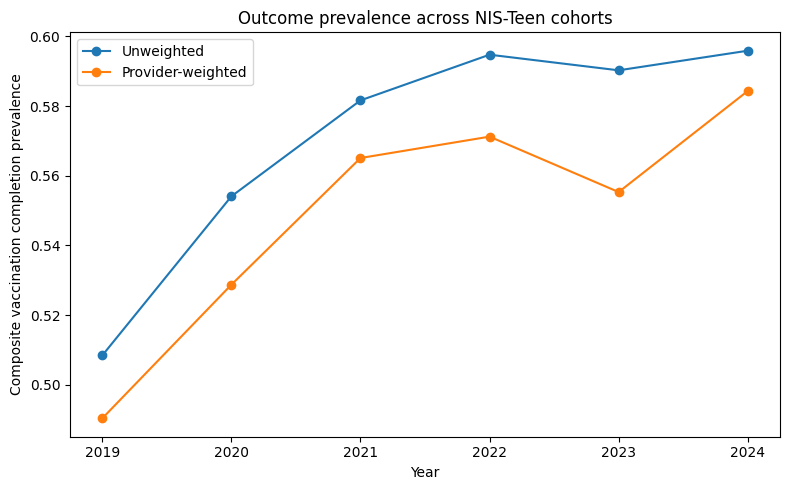

[2019] Logistic_Regression: tuning on N=13,059, held-out N=5,597
[2019] Ridge_Logistic: tuning on N=13,059, held-out N=5,597
[2019] LASSO_Logistic: tuning on N=13,059, held-out N=5,597
[2019] Random_Forest: tuning on N=13,059, held-out N=5,597
[2019] XGBoost: tuning on N=13,059, held-out N=5,597
[2020] Logistic_Regression: tuning on N=14,025, held-out N=6,011
[2020] Ridge_Logistic: tuning on N=14,025, held-out N=6,011
[2020] LASSO_Logistic: tuning on N=14,025, held-out N=6,011
[2020] Random_Forest: tuning on N=14,025, held-out N=6,011
[2020] XGBoost: tuning on N=14,025, held-out N=6,011
[2021] Logistic_Regression: tuning on N=12,529, held-out N=5,370
[2021] Ridge_Logistic: tuning on N=12,529, held-out N=5,370
[2021] LASSO_Logistic: tuning on N=12,529, held-out N=5,370
[2021] Random_Forest: tuning on N=12,529, held-out N=5,370
[2021] XGBoost: tuning on N=12,529, held-out N=5,370
[2022] Logistic_Regression: tuning on N=11,141, held-out N=4,776
[2022] Ridge_Logistic: tuning on N=11,141, h

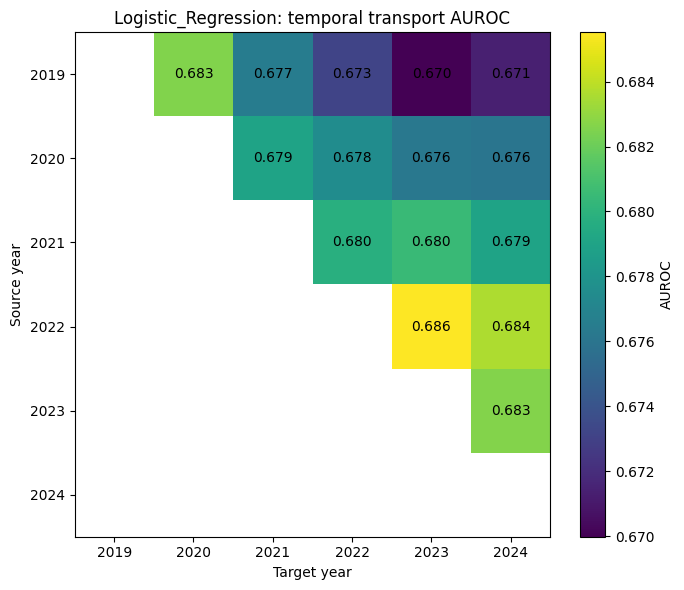

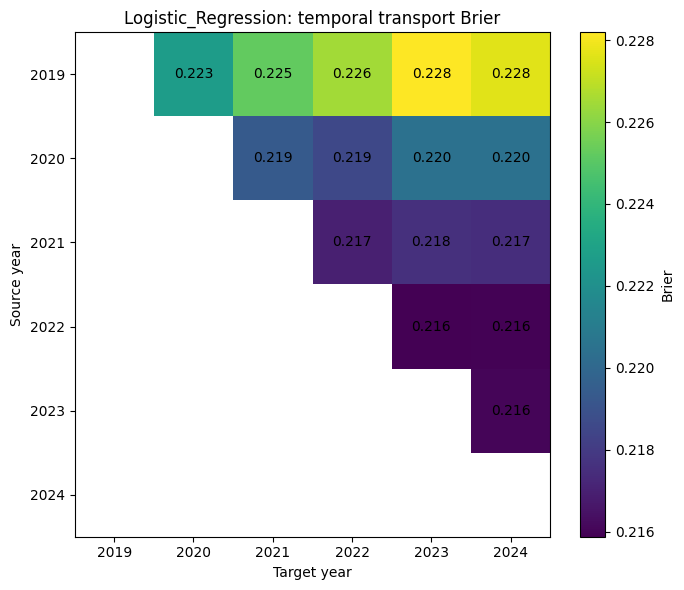

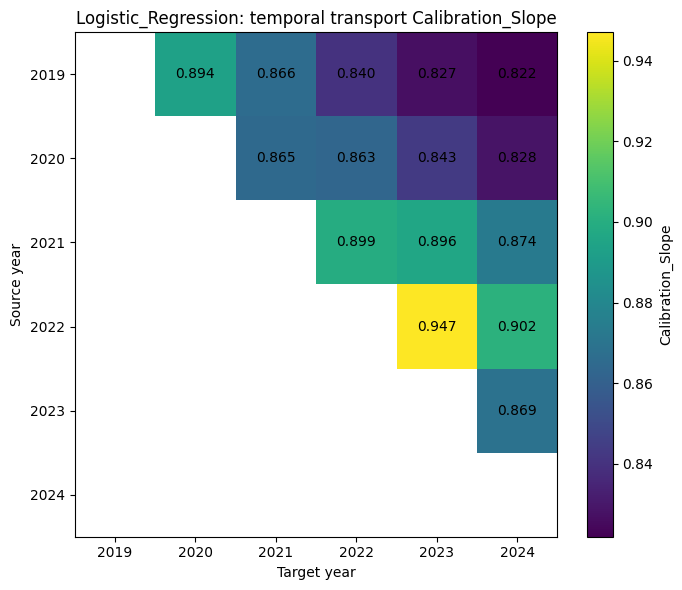

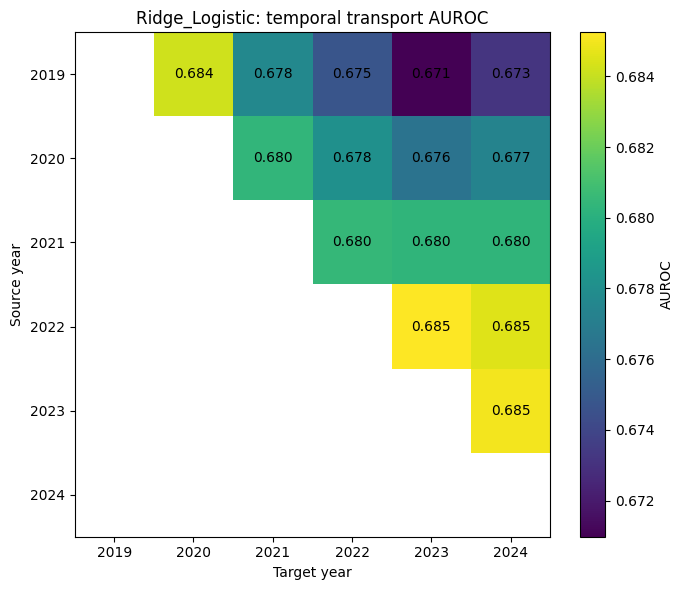

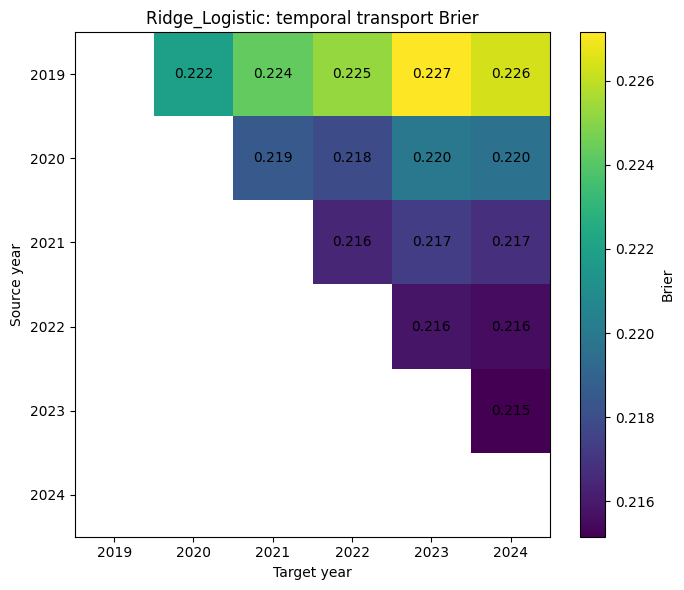

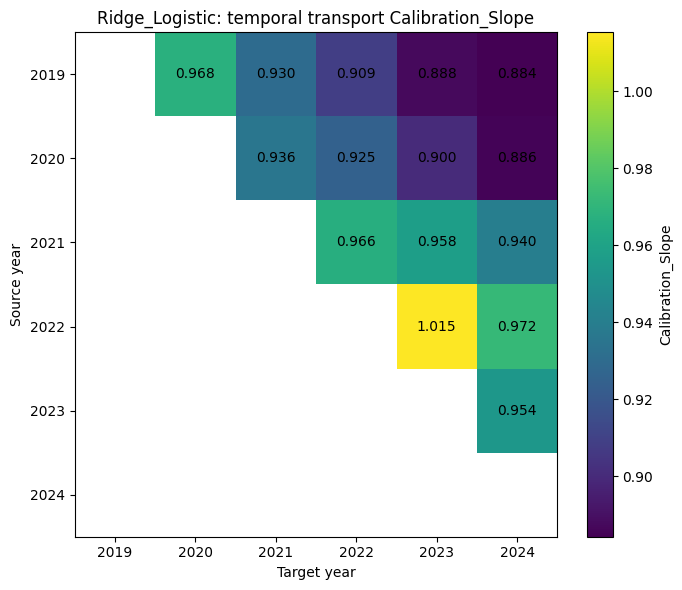

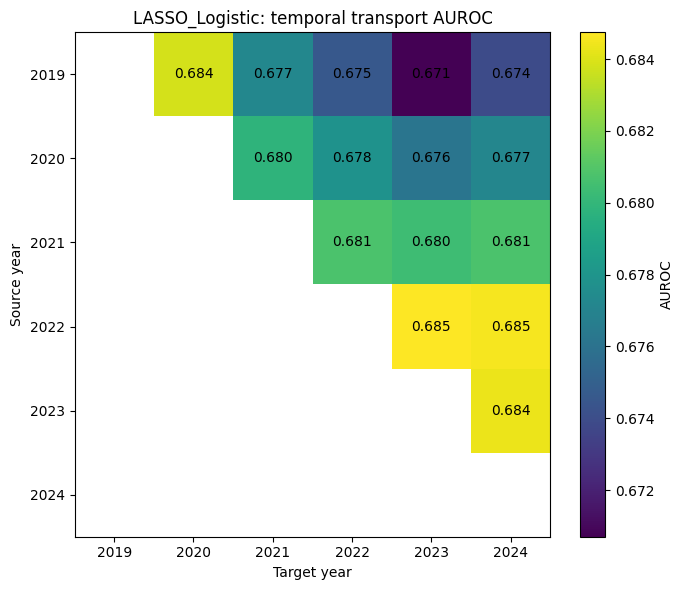

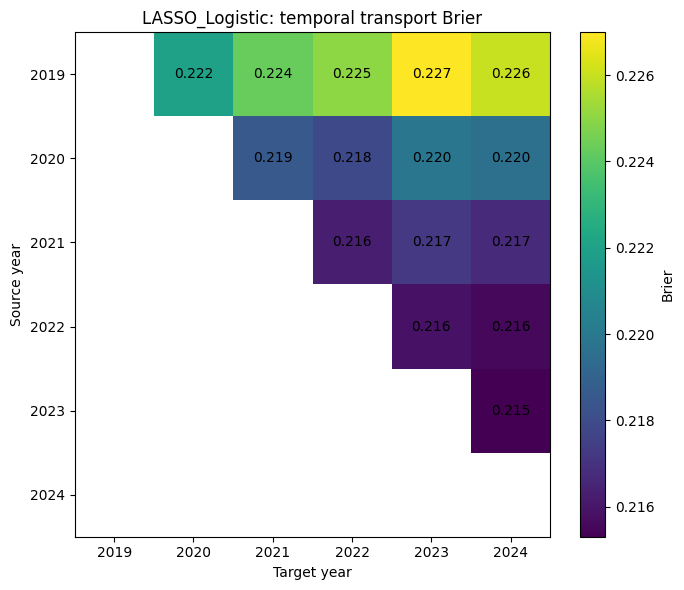

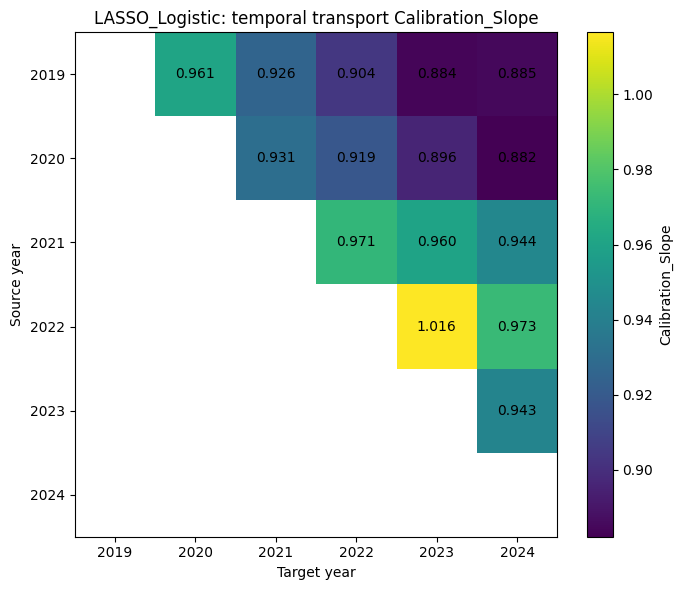

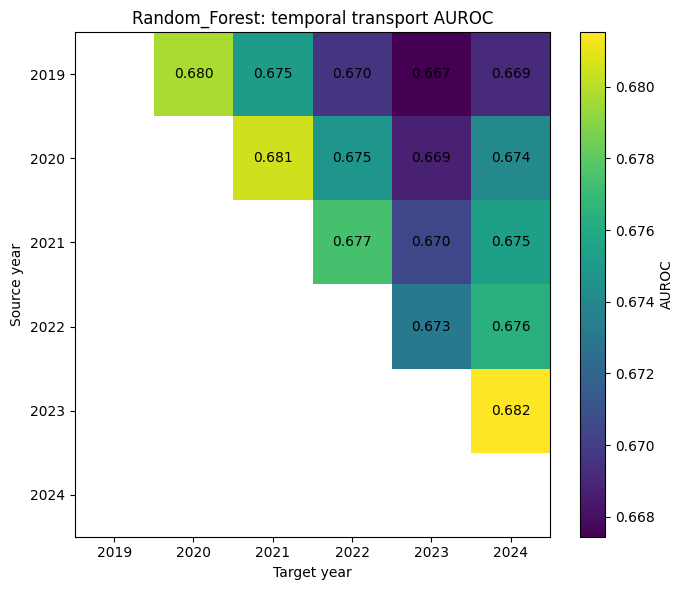

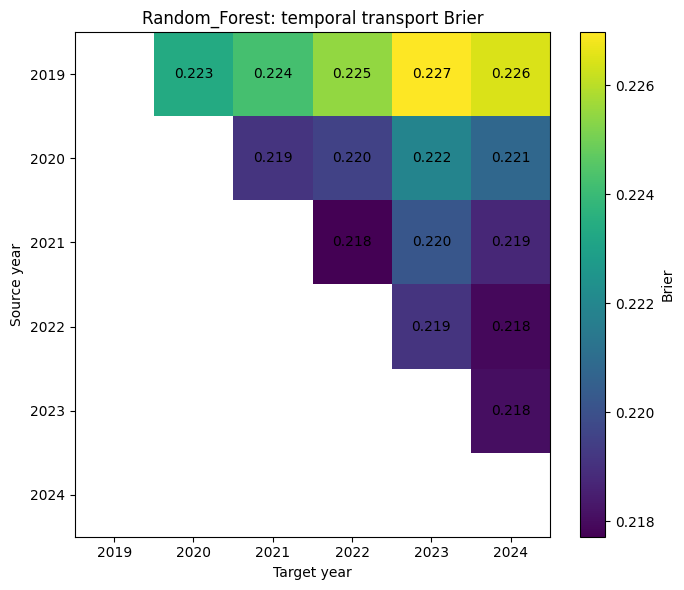

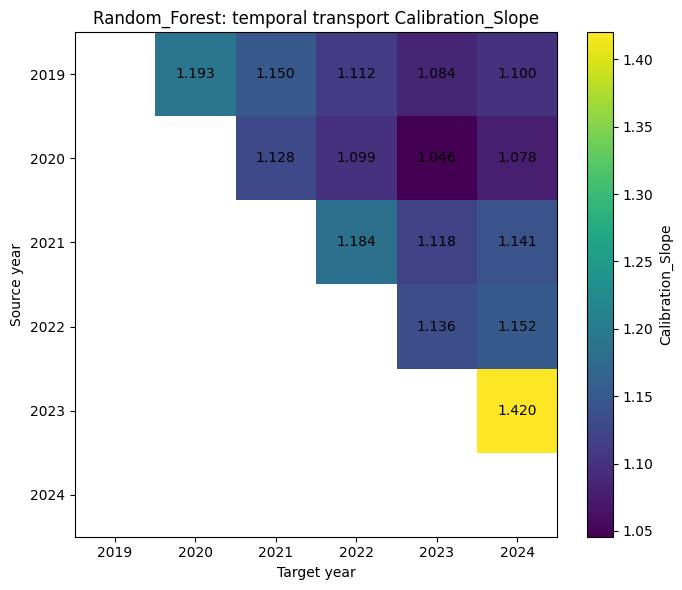

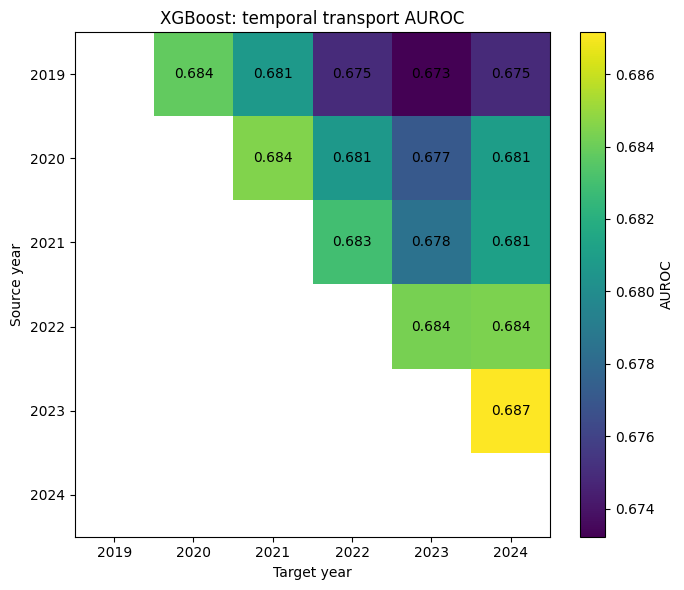

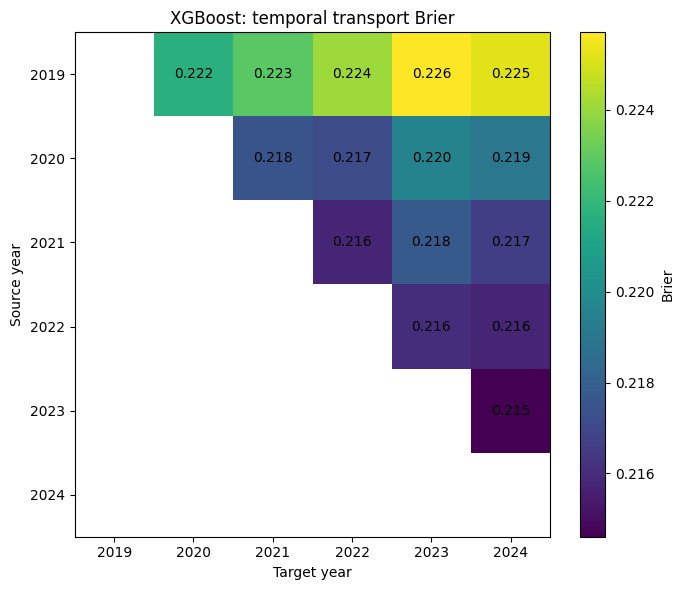

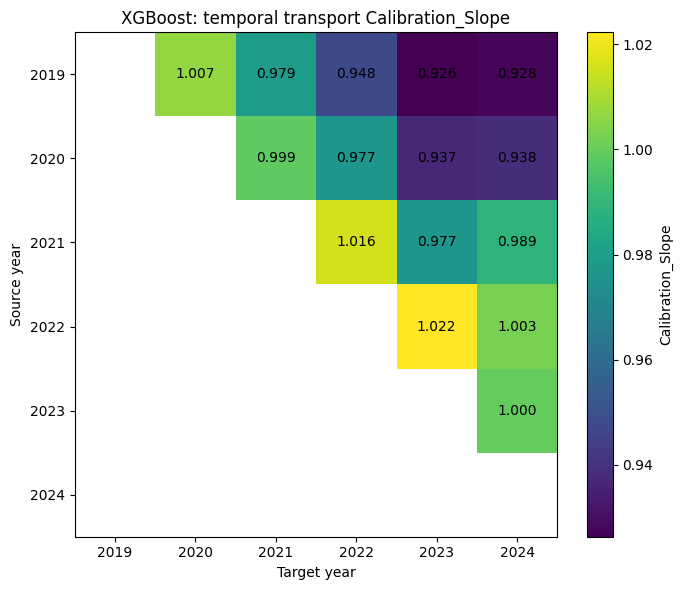

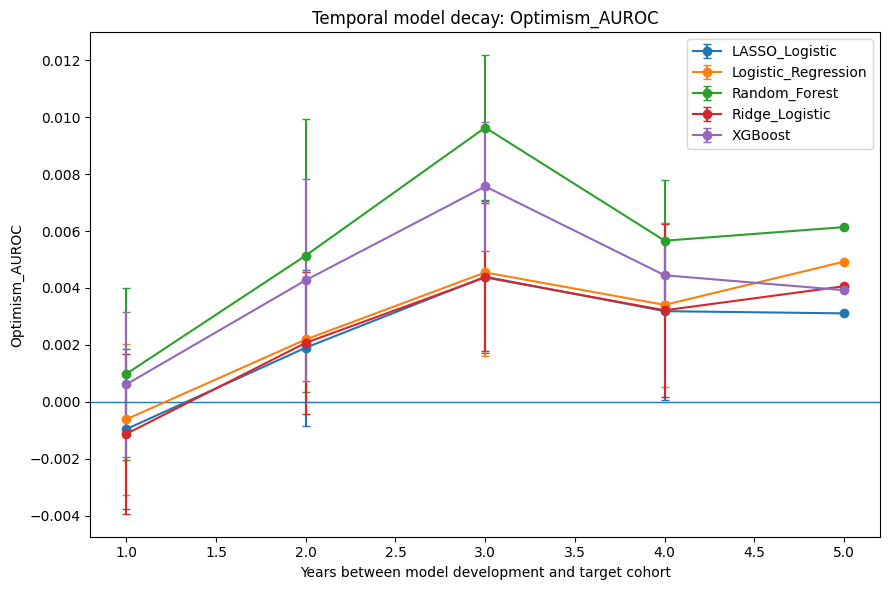

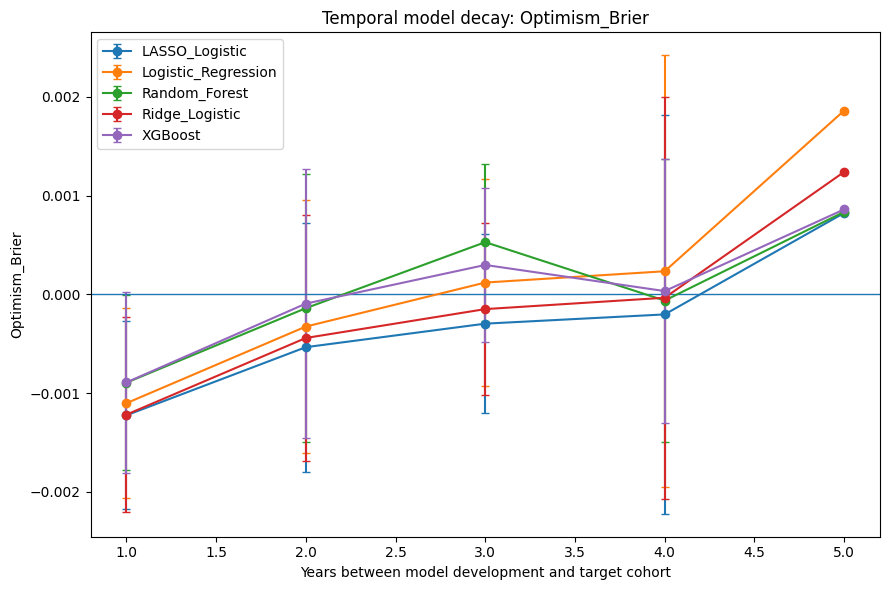

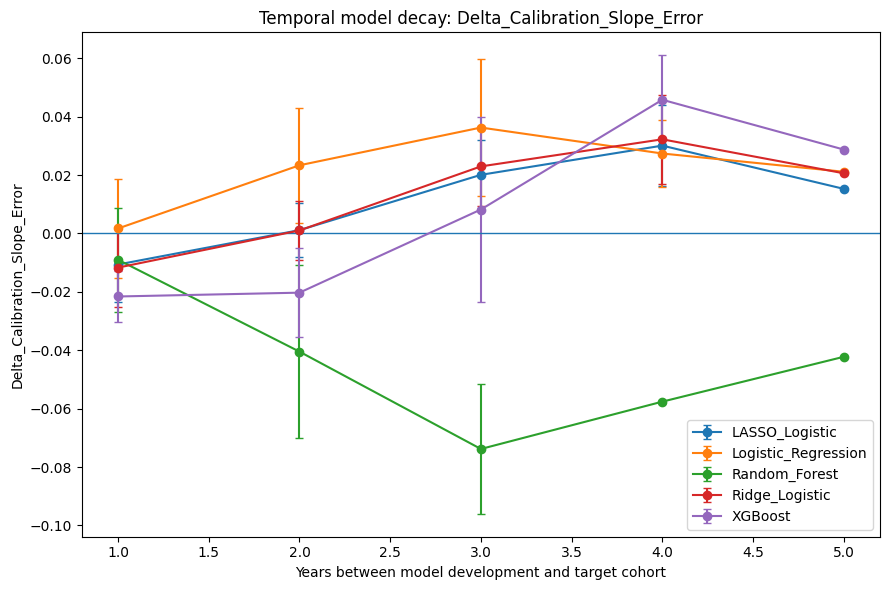

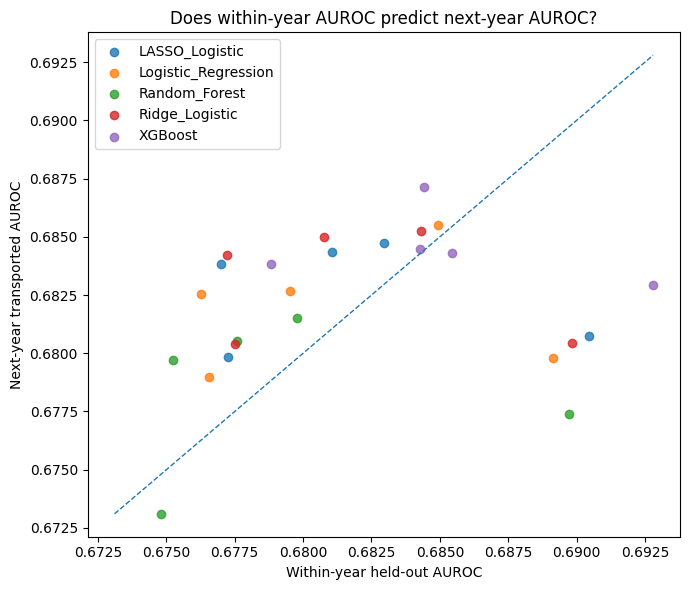

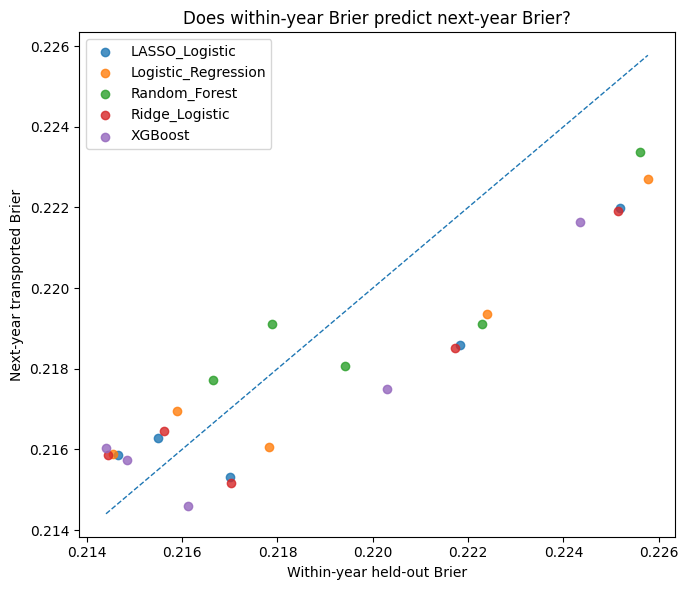

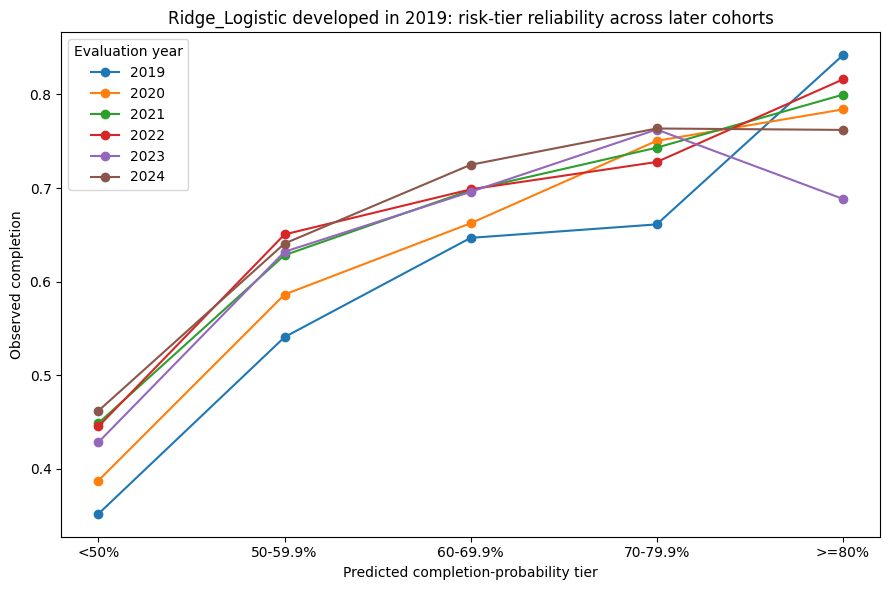


ANALYSIS COMPLETE
Output folder: /content/yesterdays_model_tomorrows_outcome
Output zip: /content/yesterdays_model_tomorrows_outcome.zip

HOW TO READ THE RESULTS
-----------------------
1. Start with STS_TABLE_1 and STS_TABLE_2.
   Ask whether models that look good within a year remain good later.

2. Use STS_TABLE_3 / 07_model_aging_and_validation_optimism.csv.
   Positive Optimism_AUROC or Optimism_Brier means internal validation
   made future performance look better than it really was.

3. Use STS_TABLE_4 / failure-pattern outputs.
   'Probability_only' means Brier clearly worsened without clear AUROC
   deterioration. That is direct evidence that ranking can remain useful
   while probability reliability ages.

4. Use the rank-agreement and model-selection files.
   These test whether the model that looks best today is actually the
   model that works best next year.

5. Use the risk-tier file to determine whether probability bands retain
   their observed meaning as the source m

In [ ]:
# ==============================================================================
# CODE CELL 23
# ==============================================================================
main()


# ==============================================================================
# NOTEBOOK MARKDOWN CELL 24
# ==============================================================================
# ## How to interpret the final STS outputs
#
# ### Start with the central evidence
#
# 1. `STS_TABLE_1_within_year_validation.csv` — what each model appeared to achieve inside its development year.
# 2. `STS_TABLE_2_future_year_transport.csv` — what those exact frozen models achieved in genuinely later cohorts.
# 3. `STS_TABLE_3_temporal_reliability_and_optimism.csv` — direct source-vs-future deterioration; the clearest table for H1 and H3.
# 4. `STS_TABLE_4_deterioration_uncertainty.csv` — bootstrap confidence intervals and the “what fails first?” classification.
# 5. `08_model_aging_summary_by_year_gap.csv` plus the aging figures — whether deterioration grows as models get older.
#
# ### Then use the supportive analyses
#
# - `13_probability_risk_tier_transportability.csv` — whether predicted probability bands retain the same observed meaning later.
# - `06c_feature_importance_stability.csv` — whether the frozen model relies on predictors in a similar order through time.
# - `06e_subgroup_temporal_deterioration.csv` — whether aging is similar across prespecified subgroups.
# - `01_feature_distribution_shift.csv` and `02_domain_classifier_shift.csv` — how different source and target predictor distributions are.
# - `STS_TABLE_5_model_selection_experiment.csv` — whether historical forward validation helps choose a family for the next unseen year.
#
# ### Interpretation patterns
#
# **Stable AUROC + worsening Brier/calibration:** ranking may remain useful while absolute probabilities become unreliable. This is one of the strongest possible findings for the project.
#
# **Increasing deterioration with larger year gap:** supports temporal aging, especially when the pattern repeats across model families.
#
# **Large same-year-to-future optimism:** shows why random internal validation is not the same as future temporal reliability.
#
# **Falling feature-rank stability:** suggests the predictive role of measured characteristics changes through time. This is supportive evidence, not proof of mechanism.
#
# **Subgroup-specific deterioration:** shows aggregate reliability can hide heterogeneity. Do not turn this into a causal explanation without additional evidence.
#
# ### Survey weights
#
# The unweighted predictive analysis asks how well the model predicts individuals in the analyzed sample. The survey-weighted sensitivity asks how performance summaries look when observations are weighted toward national population representation. They are related but not identical estimands, so report both carefully rather than treating one as a correction for the other.
#
# ### STS framing
#
# The strongest scientific story is not “we tried many ML algorithms.” It is:
#
# > Models are often validated as though performance were stationary. Repeated annual national cohorts make it possible to directly measure how discrimination, probability reliability, predictor importance, and subgroup performance change as a model ages.
#
# ### External replication
#
# After the NIS-Teen protocol is finalized and locked, the same conceptual framework can be replicated on MEPS 2020–2024 with a separately harmonized outcome and predictor set. NIS results should not be used to repeatedly redesign the method after seeing MEPS results; that would weaken MEPS as a replication.



In [ ]:
import shutil
from google.colab import files

folder = "/content/yesterdays_model_tomorrows_outcome"
zip_path = "/content/yesterdays_model_tomorrows_outcome_results"

shutil.make_archive(
    zip_path,
    "zip",
    folder
)

files.download(zip_path + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# TARGETED 1,000-REPLICATE SENSITIVITY ANALYSIS
# 2019 models -> 2024 cohort only
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Point this to your existing results folder
# ------------------------------------------------------------
# If OUTPUT_DIR is already defined by your notebook, this will use it.
# Otherwise uncomment/edit the second line.

results_dir = Path(OUTPUT_DIR)
# results_dir = Path("/content/yesterdays_model_tomorrows_outcome")

print("Reading predictions from:", results_dir)


# ------------------------------------------------------------
# 2. Load EXISTING predictions -- no model refitting
# ------------------------------------------------------------
within_pred = pd.read_csv(
    results_dir / "04_within_year_predictions.csv"
)

transport_pred = pd.read_csv(
    results_dir / "06_all_forward_transport_predictions.csv"
)


# ------------------------------------------------------------
# 3. Keep only the longest temporal comparison:
#    source = 2019, target = 2024
# ------------------------------------------------------------
source_2019 = within_pred[
    within_pred["Year"] == 2019
].copy()

target_2024 = transport_pred[
    (transport_pred["Source_Year"] == 2019)
    & (transport_pred["Target_Year"] == 2024)
].copy()


models = sorted(
    set(source_2019["Model"])
    & set(target_2024["Model"])
)

print("\nModels found:")
for model in models:
    print("  ", model)


# ------------------------------------------------------------
# 4. Run 1,000 bootstrap replicates for each model
# ------------------------------------------------------------
N_SENSITIVITY_BOOTSTRAP = 1000

rows = []

for model_index, model in enumerate(models):

    print(
        f"\n[{model_index + 1}/{len(models)}] "
        f"Bootstrapping {model}: 2019 -> 2024..."
    )

    src = source_2019[
        source_2019["Model"] == model
    ].copy()

    tgt = target_2024[
        target_2024["Model"] == model
    ].copy()

    source_y = src["Observed"].to_numpy(dtype=int)
    source_p = src["Predicted"].to_numpy(dtype=float)

    target_y = tgt["Observed"].to_numpy(dtype=int)
    target_p = tgt["Predicted"].to_numpy(dtype=float)

    # Uses the EXACT bootstrap function from your main notebook
    result = bootstrap_source_target_deltas(
        source_y=source_y,
        source_p=source_p,
        target_y=target_y,
        target_p=target_p,
        n_bootstrap=N_SENSITIVITY_BOOTSTRAP,
        seed=(
            RANDOM_STATE
            + 50000
            + model_index
        ),
    )

    result.update(
        {
            "Source_Year": 2019,
            "Target_Year": 2024,
            "Year_Gap": 5,
            "Model": model,
        }
    )

    rows.append(result)

    print(
        "   finished:",
        result["Bootstrap_N"],
        "valid replicates"
    )


# ------------------------------------------------------------
# 5. Classify failure pattern using the SAME rules
# ------------------------------------------------------------
sensitivity_1000 = pd.DataFrame(rows)

sensitivity_1000 = classify_failure_pattern(
    sensitivity_1000
)


# ------------------------------------------------------------
# 6. Save separately -- DO NOT overwrite your 250-replicate file
# ------------------------------------------------------------
output_file = (
    results_dir
    / "09b_2019_to_2024_1000_bootstrap_sensitivity.csv"
)

sensitivity_1000.to_csv(
    output_file,
    index=False,
)

print(
    "\nSaved 1,000-replicate sensitivity analysis to:"
)
print(output_file)


# ------------------------------------------------------------
# 7. Print the key results
# ------------------------------------------------------------
display_cols = [
    "Model",

    "Delta_AUROC_Observed",
    "Delta_AUROC_CI_Low",
    "Delta_AUROC_CI_High",

    "Delta_Calibration_Intercept_Abs_Observed",
    "Delta_Calibration_Intercept_Abs_CI_Low",
    "Delta_Calibration_Intercept_Abs_CI_High",

    "Delta_ECE_Observed",
    "Delta_ECE_CI_Low",
    "Delta_ECE_CI_High",

    "Delta_Calibration_Slope_Error_Observed",
    "Delta_Calibration_Slope_Error_CI_Low",
    "Delta_Calibration_Slope_Error_CI_High",

    "Failure_Pattern",
]

print("\n" + "=" * 90)
print("1,000-REPLICATE SENSITIVITY ANALYSIS: 2019 -> 2024")
print("=" * 90)

print(
    sensitivity_1000[
        display_cols
    ].round(4).to_string(index=False)
)

Reading predictions from: /content/yesterdays_model_tomorrows_outcome

Models found:
   LASSO_Logistic
   Logistic_Regression
   Random_Forest
   Ridge_Logistic
   XGBoost

[1/5] Bootstrapping LASSO_Logistic: 2019 -> 2024...
   finished: 1000 valid replicates

[2/5] Bootstrapping Logistic_Regression: 2019 -> 2024...
   finished: 1000 valid replicates

[3/5] Bootstrapping Random_Forest: 2019 -> 2024...
   finished: 1000 valid replicates

[4/5] Bootstrapping Ridge_Logistic: 2019 -> 2024...
   finished: 1000 valid replicates

[5/5] Bootstrapping XGBoost: 2019 -> 2024...
   finished: 1000 valid replicates

Saved 1,000-replicate sensitivity analysis to:
/content/yesterdays_model_tomorrows_outcome/09b_2019_to_2024_1000_bootstrap_sensitivity.csv

1,000-REPLICATE SENSITIVITY ANALYSIS: 2019 -> 2024
              Model  Delta_AUROC_Observed  Delta_AUROC_CI_Low  Delta_AUROC_CI_High  Delta_Calibration_Intercept_Abs_Observed  Delta_Calibration_Intercept_Abs_CI_Low  Delta_Calibration_Intercept_Abs_C

In [ ]:
# ============================================================
# COMPARE 250 VS 1,000 REPLICATES
# ============================================================

bootstrap_250 = pd.read_csv(
    results_dir
    / "09_bootstrap_deterioration_and_failure_patterns.csv"
)

old_5yr = bootstrap_250[
    (bootstrap_250["Source_Year"] == 2019)
    & (bootstrap_250["Target_Year"] == 2024)
].copy()

compare_columns = [
    "Model",

    "Delta_AUROC_CI_Low",
    "Delta_AUROC_CI_High",

    "Delta_Calibration_Intercept_Abs_CI_Low",
    "Delta_Calibration_Intercept_Abs_CI_High",

    "Delta_ECE_CI_Low",
    "Delta_ECE_CI_High",

    "Failure_Pattern",
]

old_compare = old_5yr[
    compare_columns
].copy()

old_compare = old_compare.rename(
    columns={
        col: f"{col}_250"
        for col in compare_columns
        if col != "Model"
    }
)

new_compare = sensitivity_1000[
    compare_columns
].copy()

new_compare = new_compare.rename(
    columns={
        col: f"{col}_1000"
        for col in compare_columns
        if col != "Model"
    }
)

comparison = old_compare.merge(
    new_compare,
    on="Model",
    how="inner",
)

comparison.to_csv(
    results_dir
    / "09c_compare_250_vs_1000_bootstrap.csv",
    index=False,
)

print("\n250 vs 1,000 replicate comparison:")
print(
    comparison.round(4).to_string(index=False)
)


250 vs 1,000 replicate comparison:
              Model  Delta_AUROC_CI_Low_250  Delta_AUROC_CI_High_250  Delta_Calibration_Intercept_Abs_CI_Low_250  Delta_Calibration_Intercept_Abs_CI_High_250  Delta_ECE_CI_Low_250  Delta_ECE_CI_High_250 Failure_Pattern_250  Delta_AUROC_CI_Low_1000  Delta_AUROC_CI_High_1000  Delta_Calibration_Intercept_Abs_CI_Low_1000  Delta_Calibration_Intercept_Abs_CI_High_1000  Delta_ECE_CI_Low_1000  Delta_ECE_CI_High_1000 Failure_Pattern_1000
Logistic_Regression                 -0.0206                   0.0107                                      0.3421                                       0.4353                0.0525                 0.0750    Calibration_only                  -0.0203                    0.0111                                       0.3447                                        0.4362                 0.0506                  0.0733     Calibration_only
     Ridge_Logistic                 -0.0198                   0.0117                              